### Load Packages

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams as rc
import matplotlib
import os
import math
import matplotlib.colors as mcolors
import torch
import gpytorch
from pyproj import Proj, transform
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from pickle import dump, load
import linear_operator
import random
from sklearn.cluster import KMeans
from matplotlib import gridspec
import geopandas as gpd
from shapely.geometry import Polygon
import skgstat as skg

configs = {
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'font.sans-serif': ['Arial'],
     #'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    #'font.sans-serif': ['Palatino Linotype', 'Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    'axes.grid': True,
    'grid.alpha': 0.5,
    'grid.linestyle': '--',
    'mathtext.fontset': "cm",
    # 'mathtext.rm': "asana math",
    # 'mathtext.cal': "asana math",
    "font.size": 20,
    # 'axes.labelsize': 'large',
    # 'axes.labelpad': 8.0,
    # 'xtick.major.pad': 9.0,
}
rc.update(configs)

In [2]:
cmap = matplotlib.colormaps.get_cmap("coolwarm")
red_color = cmap(0.9)
blue_color = cmap(0.1)
gray_color = cmap(0.5)

color_maps = {
    "input": gray_color,
    "Expected": red_color,
    "Predicted": blue_color,
}

### Define Variables

* define model name

In [3]:
#model column names (input, output)
cn_x = ['vs_depth','Z_2.5','surf_elevation','easting','northing'] #output
cn_y = 'diff'                                                     #input

#data percentiles for test1 and test2
prc_test1 = 0.05
prc_test2 = 0.05

#define random seed
np.random.seed(1)

#define output directories
dir_out = '../Data/Vel_data/'
dir_fig = '../Data/Figure/'
dir_model = './'

#define iteration numbers
iter_num = 2500

# container for hyper parameters
hyper_parameters = {
    'stat_z':         [],
    'stat_z2.5':      [],
    'stat_elevation': [],
    'stat_scale':     [],
    'stat_scale_id':     [],
    'noise':         []}

### Read Input Files

In [4]:
#read the entire data
df_measure = pd.read_csv(dir_out+'Training_data/df_measure.txt', encoding='utf-8')
df_measure = df_measure.rename(columns={'metadata_id': 'velocity_metadata_id', 'z_2.5': 'Z_2.5',
                                       'vs_middle_depth': 'vs_depth'})
df_measure

,velocity_metadata_id,vs_depth,vs_value,vs_top_depth,vs_bottom_depth,test_id,velocity_name,velocity_method,velocity_date,velocity_quality,...,terrain_class,site_easting,site_northing,test_easting,test_northing,vs_model,surf_elevation,Z_2.5,diff,basin_idnum
0,610,1.00,155.0,0.5,1.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,938.187,251.052,2380.0,-1.800524,2
1,610,2.00,170.2,1.5,2.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,939.068,251.052,2380.0,-1.707914,2
2,610,3.00,196.5,2.5,3.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,939.949,251.052,2380.0,-1.565163,2
3,610,4.00,191.9,3.5,4.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,940.830,251.052,2380.0,-1.589788,2
4,610,5.00,202.0,4.5,5.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,941.711,251.052,2380.0,-1.539431,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11026,2479,12.60,354.0,9.3,15.9,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,894.882,54.938,3620.0,-0.927395,1
11027,2479,21.15,387.0,15.9,26.4,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,899.010,54.938,3620.0,-0.842869,1
11028,2479,34.80,445.0,26.4,43.2,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,905.600,54.938,3620.0,-0.710523,1
11029,2479,56.60,540.0,43.2,70.0,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,916.125,54.938,3620.0,-0.528584,1


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

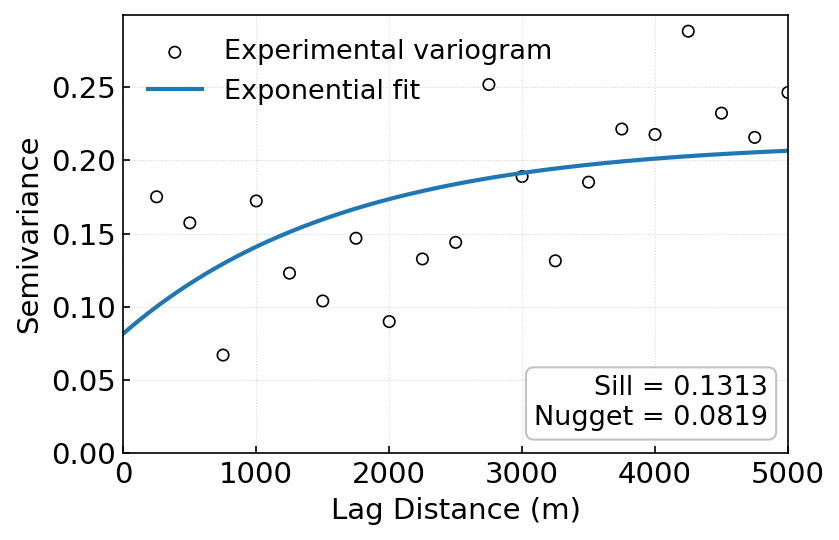

In [5]:
coords = df_measure[["site_easting", "site_northing"]].to_numpy()
values = df_measure["diff"].to_numpy()

V = skg.Variogram(
    coordinates=coords,
    values=values,
    model="exponential",
    n_lags=20,
    maxlag=5000,
    normalize=False,
    use_nugget=True)

params = V.parameters
variogram_range = params[0]
sill = params[1]
nugget = params[2]
bins = V.bins
experimental = V.experimental
valid = np.isfinite(experimental)
bins_valid = bins[valid]
experimental_valid = experimental[valid]


h = np.linspace(0,10000,500)
fitted = V.fitted_model(h)
fig, ax = plt.subplots(figsize=(6, 4),dpi=150)

ax.scatter(bins_valid,experimental_valid,s=30,facecolors="none",edgecolors="black",linewidth=0.8,label="Experimental variogram")
ax.plot(h,fitted,linewidth=2,label="Exponential fit")

param_text = (f"Sill = {sill:.4f}\n" f"Nugget = {nugget:.4f}")

ax.text(0.97,0.05,param_text,transform=ax.transAxes,horizontalalignment="right",verticalalignment="bottom",fontsize=13,
    bbox=dict(boxstyle="round",
        facecolor="white",
        alpha=0.8,
        edgecolor="0.7"))

ax.set_xlim(0,5000)
ax.set_ylim(bottom=0)
ax.set_xlabel("Lag Distance (m)", fontsize = 14)
ax.set_ylabel( "Semivariance", fontsize = 14)
ax.tick_params(labelsize =14)
ax.legend(frameon=False,loc="upper left", fontsize = 13)
ax.grid(True,linestyle=":",linewidth=0.5,alpha=0.5)
fig.tight_layout()


fig.savefig(
    dir_fig + "semivariogram.png",
    format="png",
    dpi=300
)

In [6]:
idx_max_depth = df_measure.groupby('velocity_metadata_id')['vs_bottom_depth'].idxmax()
df_vs30_maxdepth = df_measure.loc[idx_max_depth, ['velocity_metadata_id', 'vs_bottom_depth', 'vs30']].reset_index(drop=True)
df_vs30_maxdepth = df_vs30_maxdepth.rename(columns={'vs30': 'vs_30'})
df_vs30_maxdepth

,velocity_metadata_id,vs_bottom_depth,vs_30
0,6,249.5,269.050
1,11,57.0,204.872
2,12,59.5,257.209
3,13,91.4,370.521
4,14,89.5,715.124
...,...,...,...
624,2475,35.0,384.342
625,2476,100.0,289.477
626,2477,140.0,355.262
627,2478,100.0,382.593


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.
findfont: Font family ['sans'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'sans' not found because none of the following families were found: Arial
findfont: Font family ['sans'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'sans' not f

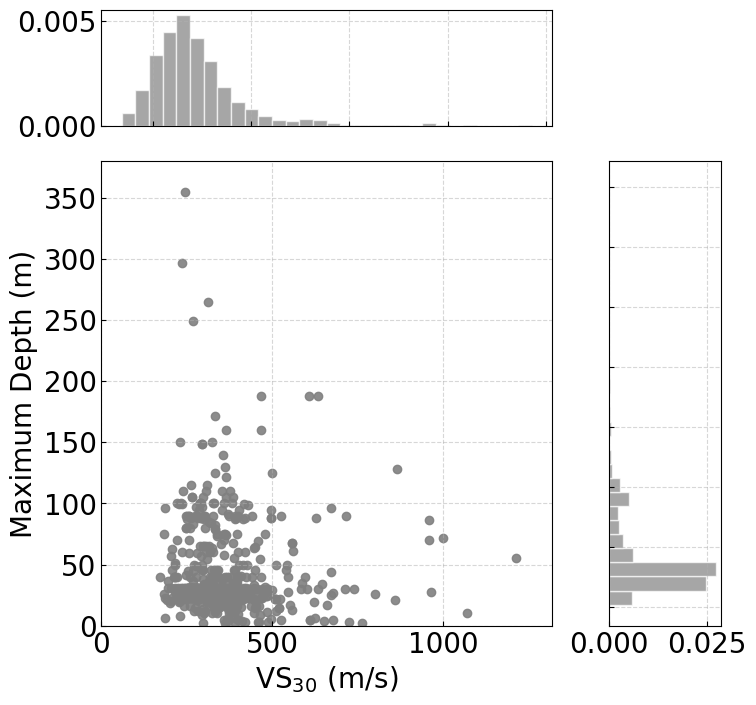

In [7]:
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams["mathtext.rm"] = "Arial"
plt.rcParams["mathtext.it"] = "Arial:italic"
plt.rcParams["mathtext.bf"] = "Arial:bold"

x = df_vs30_maxdepth['vs_30']
y = df_vs30_maxdepth['vs_bottom_depth']

gs = gridspec.GridSpec(
    2, 2,
    width_ratios=[4, 1],
    height_ratios=[1, 4],
    wspace=0.2
)

fig = plt.figure(figsize=(8, 8))

ax_joint = plt.subplot(gs[1, 0])
ax_joint.scatter(x, y, color='gray', alpha=0.9)
ax_joint.set(xlim=(0, 1320), ylim=(0, 380))

ax_joint.set_xlabel(r"$\mathrm{VS}_{30}$ (m/s)", fontname="Arial")
ax_joint.set_ylabel("Maximum Depth (m)", fontname="Arial")

ax_marg_x = plt.subplot(gs[0, 0])
ax_marg_x.hist(
    x, bins=30, align='mid',
    color='gray', edgecolor='white',
    alpha=0.7, density=True
)
ax_marg_x.tick_params(labelbottom=False)

ax_marg_y = plt.subplot(gs[1, 1])
ax_marg_y.hist(
    y, bins=30, orientation='horizontal',
    color='gray', align='mid',
    edgecolor='white', alpha=0.7,
    density=True
)
ax_marg_y.tick_params(labelleft=False)

plt.subplots_adjust(wspace=0.12, hspace=0.12)

fig.savefig(
    dir_fig + 'vs_distribution.png',
    format='png',
    dpi=300,
    bbox_inches='tight'
)

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

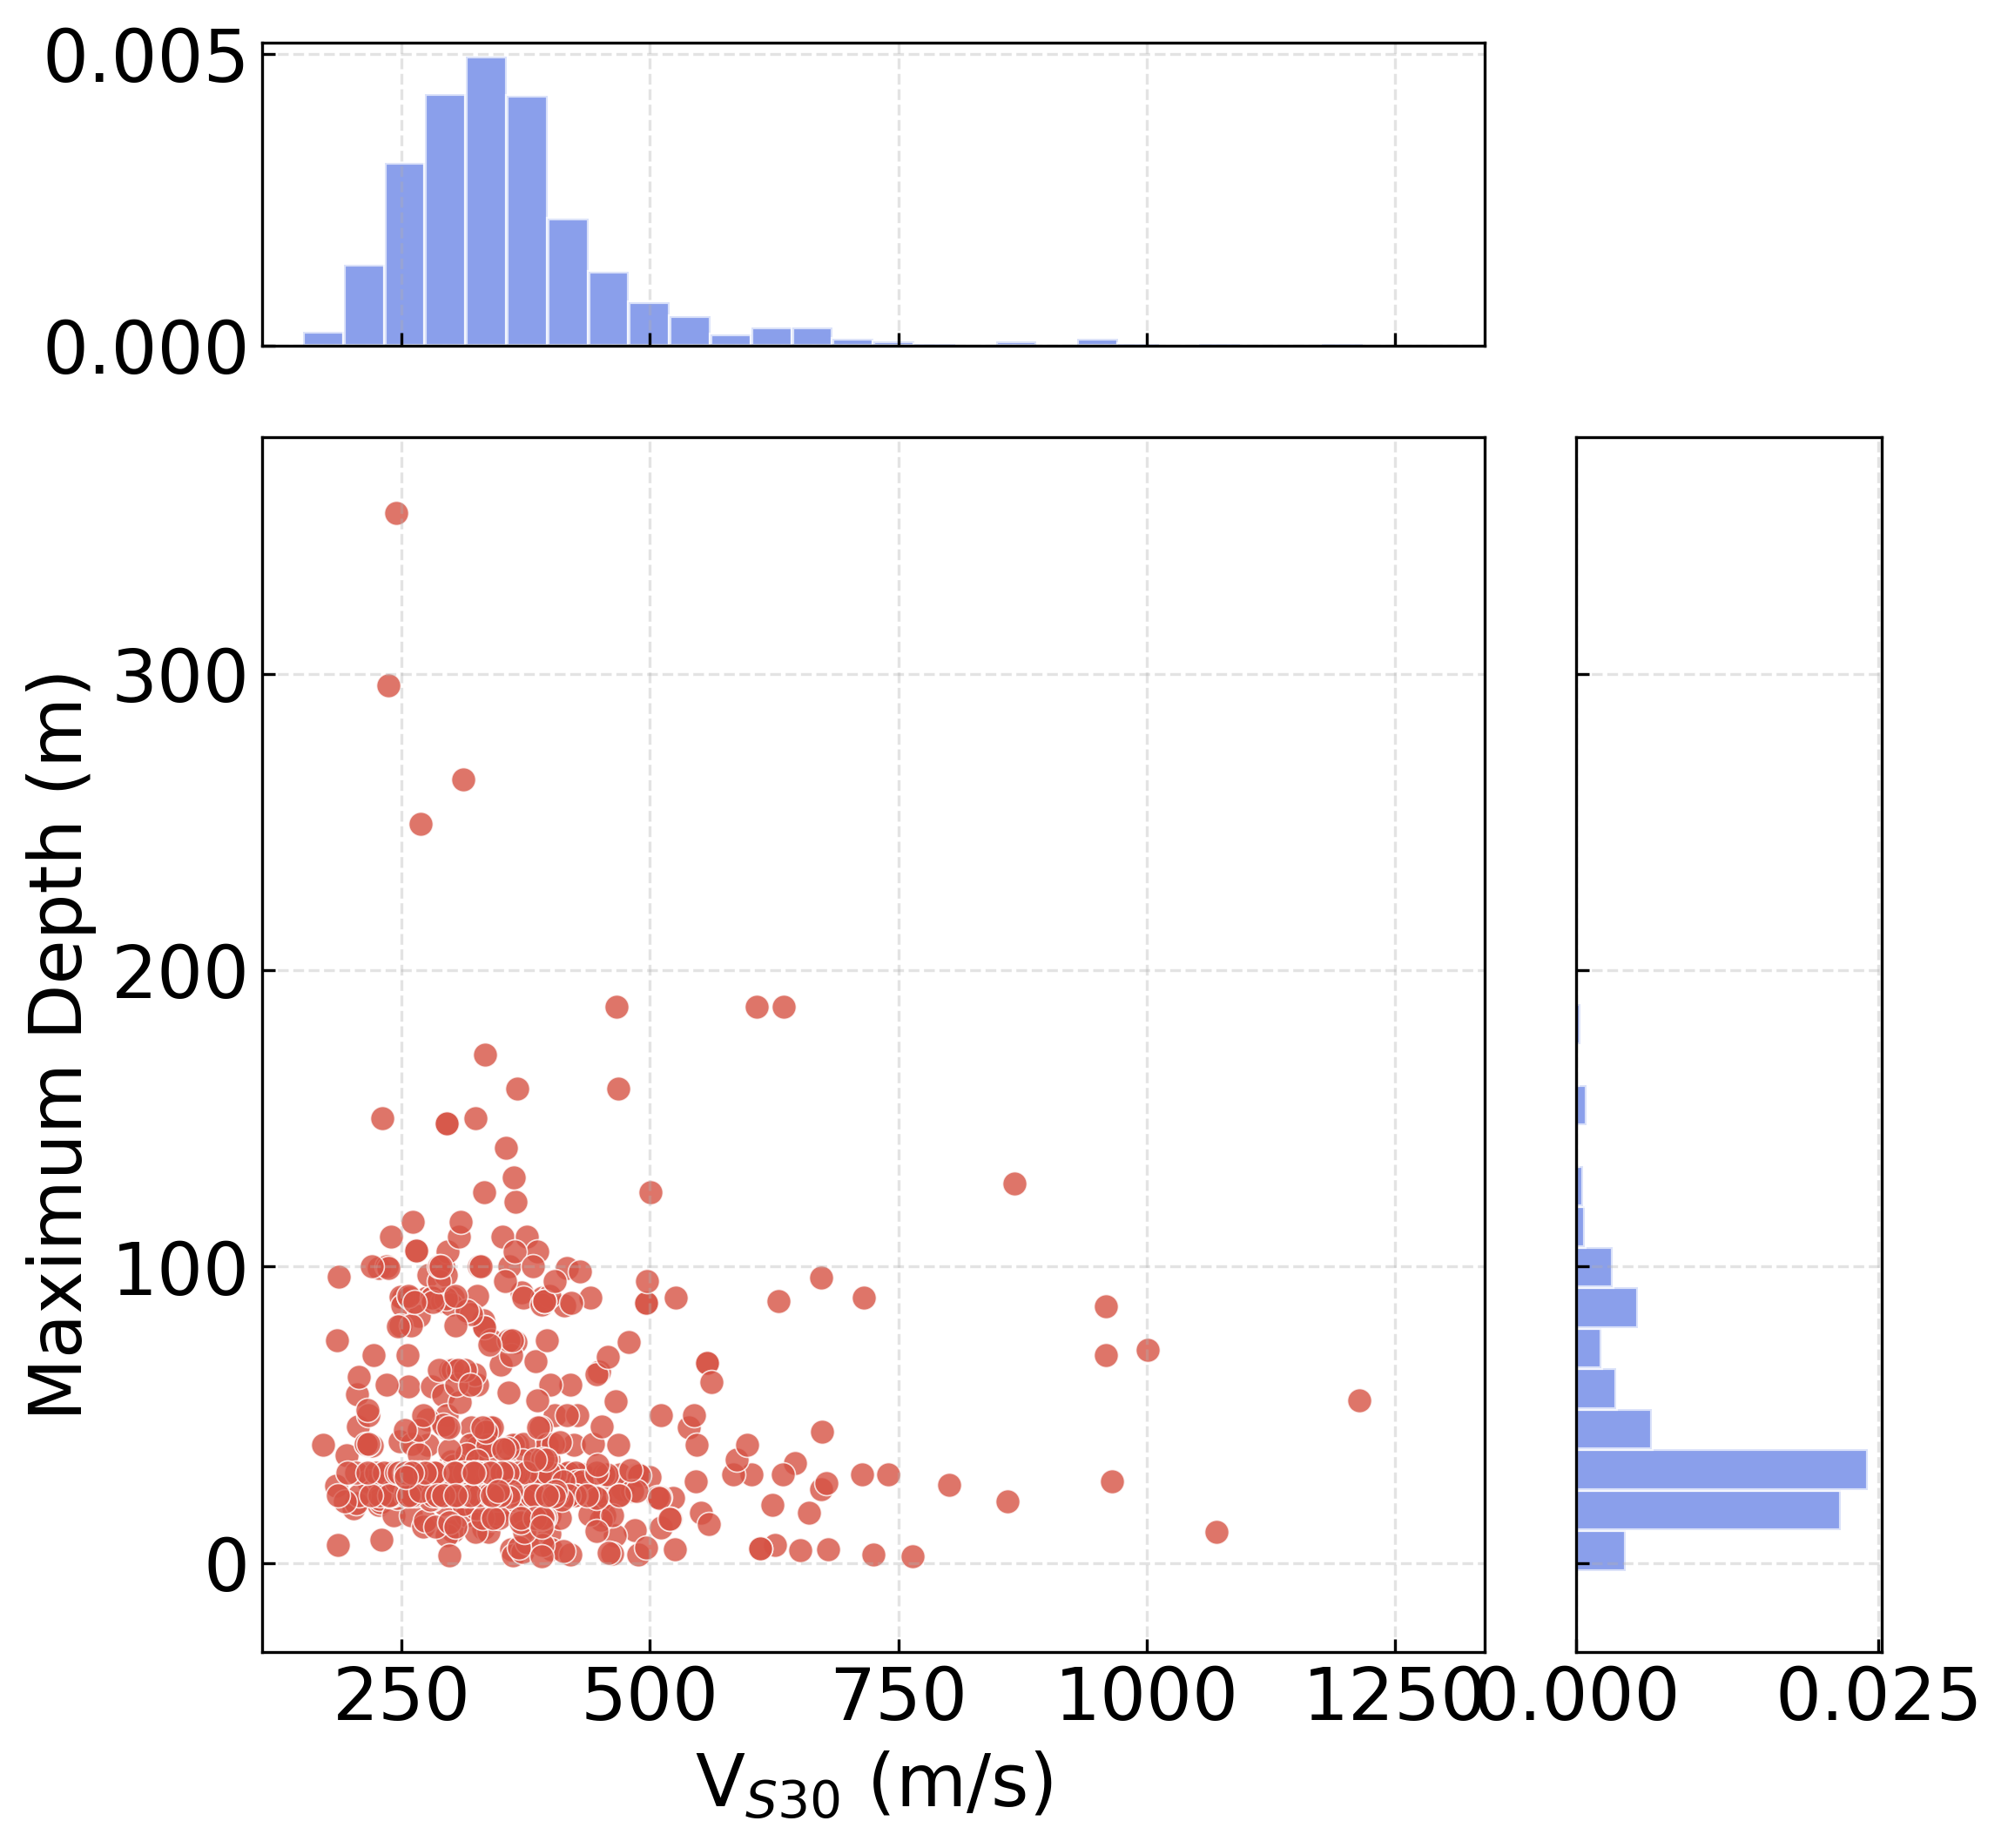

In [8]:
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams["mathtext.rm"] = "Arial"
plt.rcParams["mathtext.it"] = "Arial:italic"
plt.rcParams["mathtext.bf"] = "Arial:bold"
x = df_vs30_maxdepth["vs_30"]
y = df_vs30_maxdepth["vs_bottom_depth"]

xmin, xmax = 110, 1340
ymin, ymax = -30, 380

fig = plt.figure(figsize=(8, 8), dpi=300)

gs = gridspec.GridSpec(
    2, 2,
    width_ratios=[4, 1],
    height_ratios=[1, 4],
    wspace=0.12,
    hspace=0.12
)

ax_joint = fig.add_subplot(gs[1, 0])
ax_marg_x = fig.add_subplot(gs[0, 0], sharex=ax_joint)
ax_marg_y = fig.add_subplot(gs[1, 1], sharey=ax_joint)

ax_joint.scatter(
    x, y,
    s=45,
    color=red_color,
    alpha=0.8,
    edgecolor="white",
    linewidth=0.4
)

ax_joint.set_xlim(xmin, xmax)
ax_joint.set_ylim(ymin, ymax)

ax_joint.set_xlabel(r"$\mathrm{V}_{S30}$ (m/s)", fontsize=20)
ax_joint.set_ylabel("Maximum Depth (m)", fontsize=20)

ax_joint.grid(True, linestyle="--", alpha=0.35)

ax_marg_x.hist(
    x,
    bins=30,
    range=(xmin, xmax),   
    color=blue_color,
    edgecolor="white",
    alpha=0.7,
    density=True
)

ax_marg_x.set_xlim(xmin, xmax)
ax_marg_x.tick_params(labelbottom=False)
ax_marg_x.grid(True, linestyle="--", alpha=0.35)


ax_marg_y.hist(
    y,
    bins=30,
    range=(ymin, ymax),    
    orientation="horizontal",
    color=blue_color,
    edgecolor="white",
    alpha=0.7,
    density=True
)

ax_marg_y.set_ylim(ymin, ymax)
ax_marg_y.tick_params(labelleft=False)
ax_marg_y.grid(True, linestyle="--", alpha=0.35)

plt.setp(ax_marg_x.get_xticklabels(), visible=False)
plt.setp(ax_marg_y.get_yticklabels(), visible=False)

fig.savefig(
    dir_fig + "vs_distribution.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

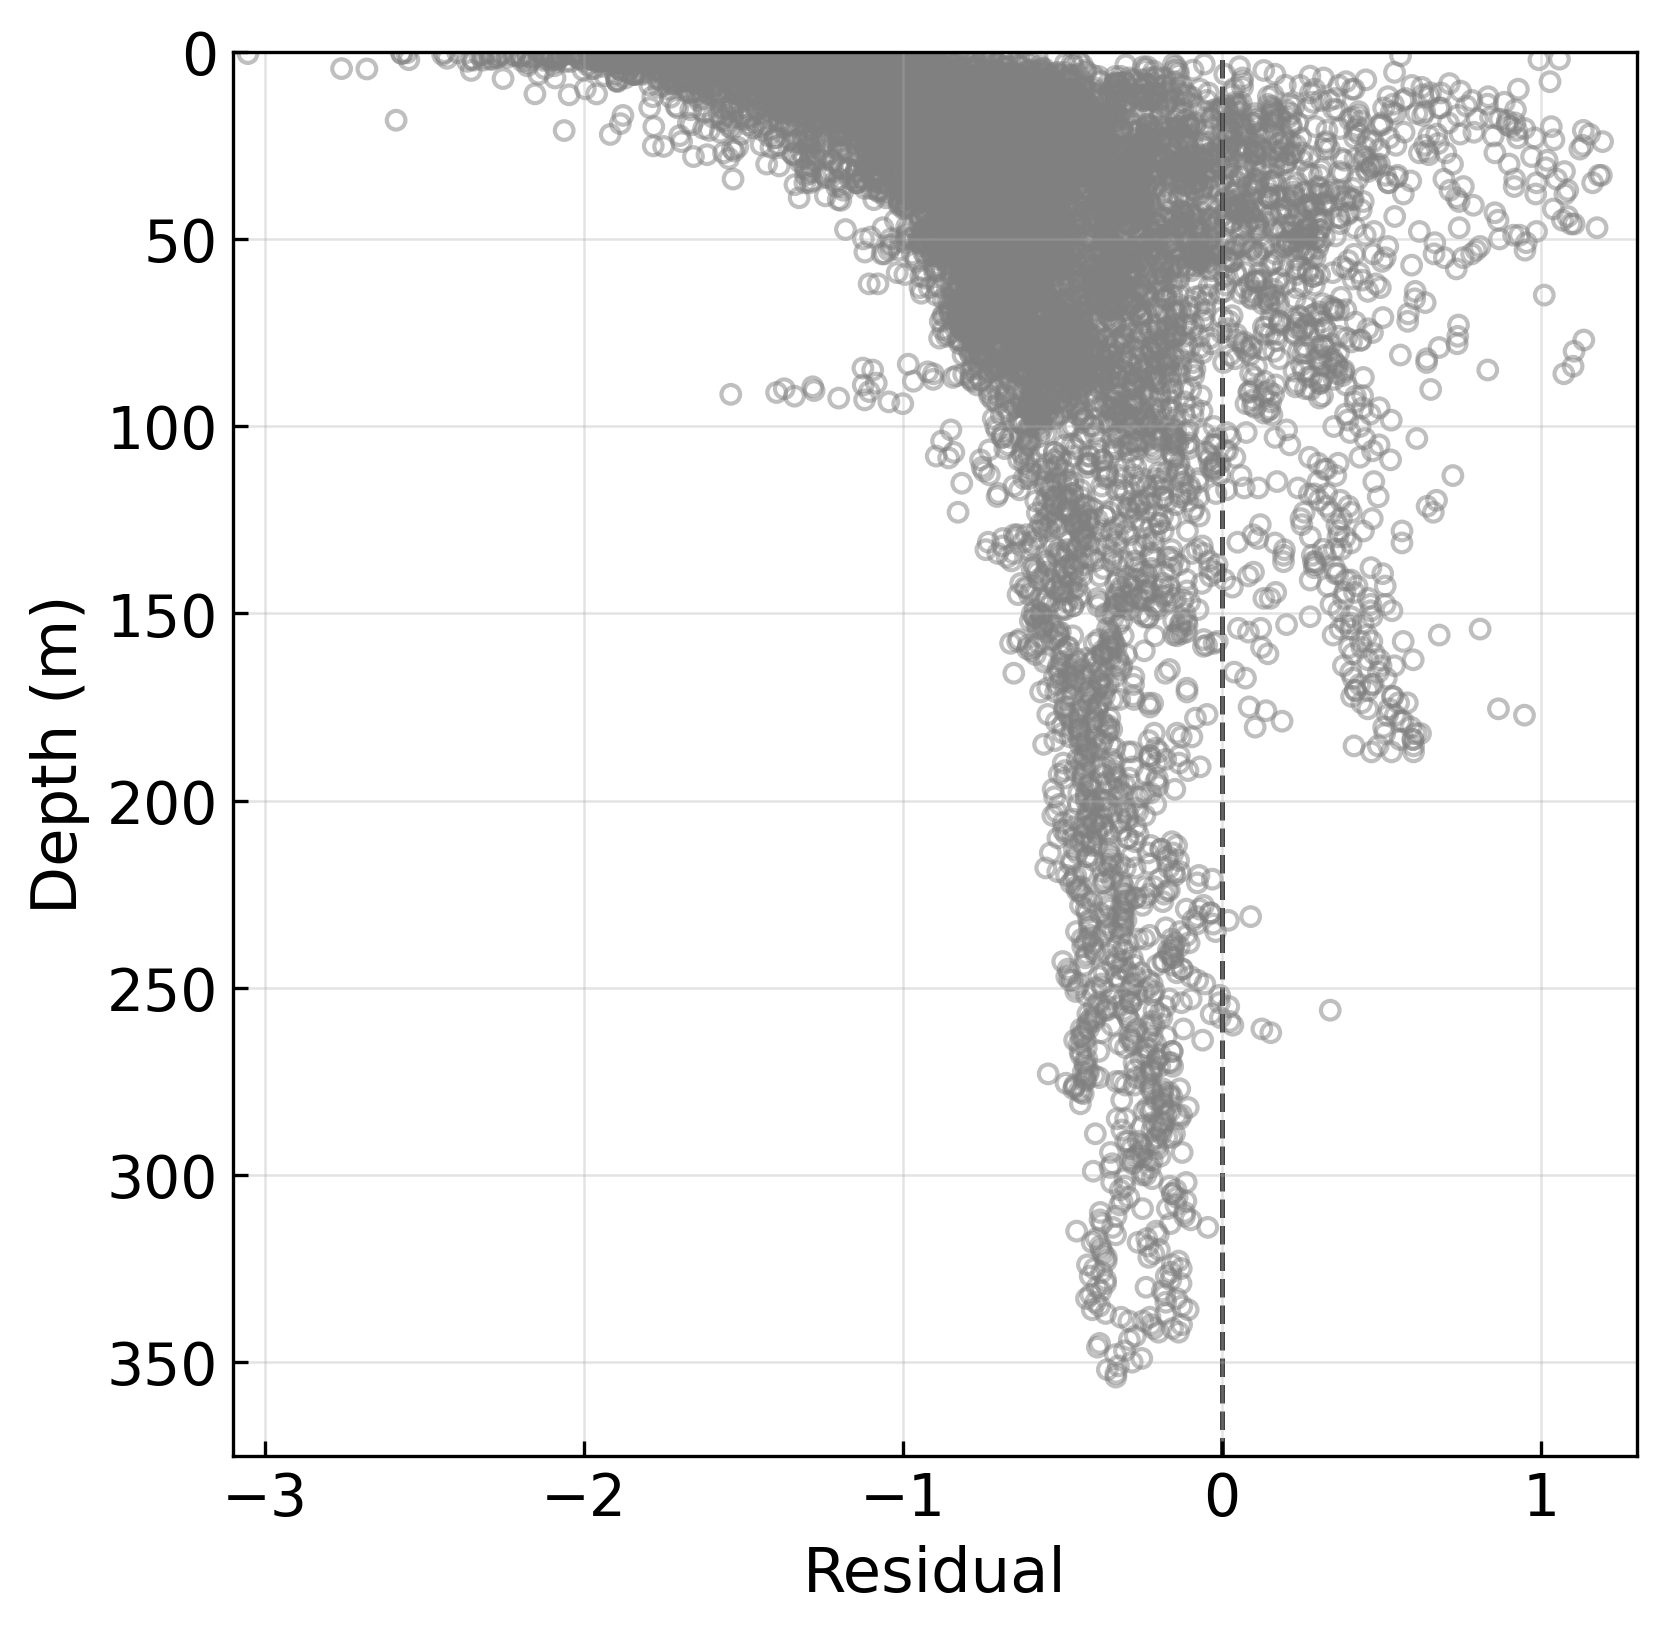

In [9]:
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams["mathtext.rm"] = "Arial"
plt.rcParams["mathtext.it"] = "Arial:italic"
plt.rcParams["mathtext.bf"] = "Arial:bold"
plt.rcParams["font.size"] = 14

fig, ax = plt.subplots(1, 1, figsize=(6, 6), dpi=300)


ax.scatter(
    df_measure['diff'], df_measure['vs_depth'],
    s=20,
    facecolors="none",
    edgecolors="gray",
    linewidths=1,
    alpha=0.5,
    label="_nolegend_"
)

ax.axvline(
    0,
    color="0.25",
    linestyle="--",
    linewidth=1.2,
    zorder=1
)


ax.set_xlim(-3.1, 1.3)
ax.set_ylim(375, 0)

ax.set_xlabel("Residual", fontsize=15)
ax.set_ylabel("Depth (m)", fontsize=15)

ax.set_box_aspect(1)

ax.grid(
    True,
    linestyle="-",
    linewidth=0.6,
    alpha=0.35
)

fig.subplots_adjust(
    left=0.18,
    right=0.96,
    bottom=0.16,
    top=0.96
)

fig.savefig(
    dir_fig + "vs_data_cleaned.png",
    format="png",
    dpi=300
)

plt.show()


In [10]:
df_sonic = pd.read_csv(dir_out+'Training_data/df_sonic.txt', encoding='utf-8')
df_sonic = df_sonic.rename(columns={'X': 'easting', 'Y': 'northing',
                                       'depth': 'vs_depth'})
df_sonic

,DEPTH_m,velocity_mps,easting,northing,source_file,TVDSS,velocity,velocity_metadata_id,longitude,latitude,vs_UCVM,vp_UCVM,surf_elevation,ratio,vs,vs_depth,Z_2.5,diff,basin_idnum
0,43.5280,1713.535764,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,43.528000,1702.435158,-29,-118.218003,33.912748,867.819,1684.427,23.596,0.515201,877.096827,67.124000,4400.0,0.010634,1
1,53.5280,1756.154846,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,53.528000,1723.341882,-29,-118.218003,33.912748,871.262,1692.589,23.596,0.514751,887.092079,77.124000,4400.0,0.018006,1
2,63.5280,1738.138676,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,63.528000,1750.140249,-29,-118.218003,33.912748,874.706,1700.750,23.596,0.514306,900.107703,87.124000,4400.0,0.028627,1
3,73.5280,1699.290684,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,73.528000,1779.210020,-29,-118.218003,33.912748,878.150,1708.912,23.596,0.513865,914.273689,97.124000,4400.0,0.040313,1
4,83.5280,1748.027201,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,83.528000,1806.930958,-29,-118.218003,33.912748,881.593,1717.073,23.596,0.513428,927.728573,107.124000,4400.0,0.051009,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3177,1956.3772,3072.301908,387298.0938,3767711.984,tuo_2,1873.377197,3072.714253,-28,-118.221002,34.044045,2107.562,3453.733,83.353,0.610227,1875.053977,1956.730197,2500.0,-0.116894,1
3178,1966.3772,3274.496954,387298.0938,3767711.984,tuo_2,1883.377197,3273.990138,-28,-118.221002,34.044045,2115.348,3464.896,83.353,0.610508,1998.798374,1966.730197,2500.0,-0.056673,1
3179,1976.3772,3338.298432,387298.0938,3767711.984,tuo_2,1893.377197,3338.257238,-28,-118.221002,34.044045,2123.133,3476.058,83.353,0.610788,2038.966008,1976.730197,2500.0,-0.040450,1
3180,1986.3772,3316.756804,387298.0938,3767711.984,tuo_2,1903.377197,3316.470704,-28,-118.221002,34.044045,2130.919,3487.221,83.353,0.611065,2026.579456,1986.730197,2500.0,-0.050204,1


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

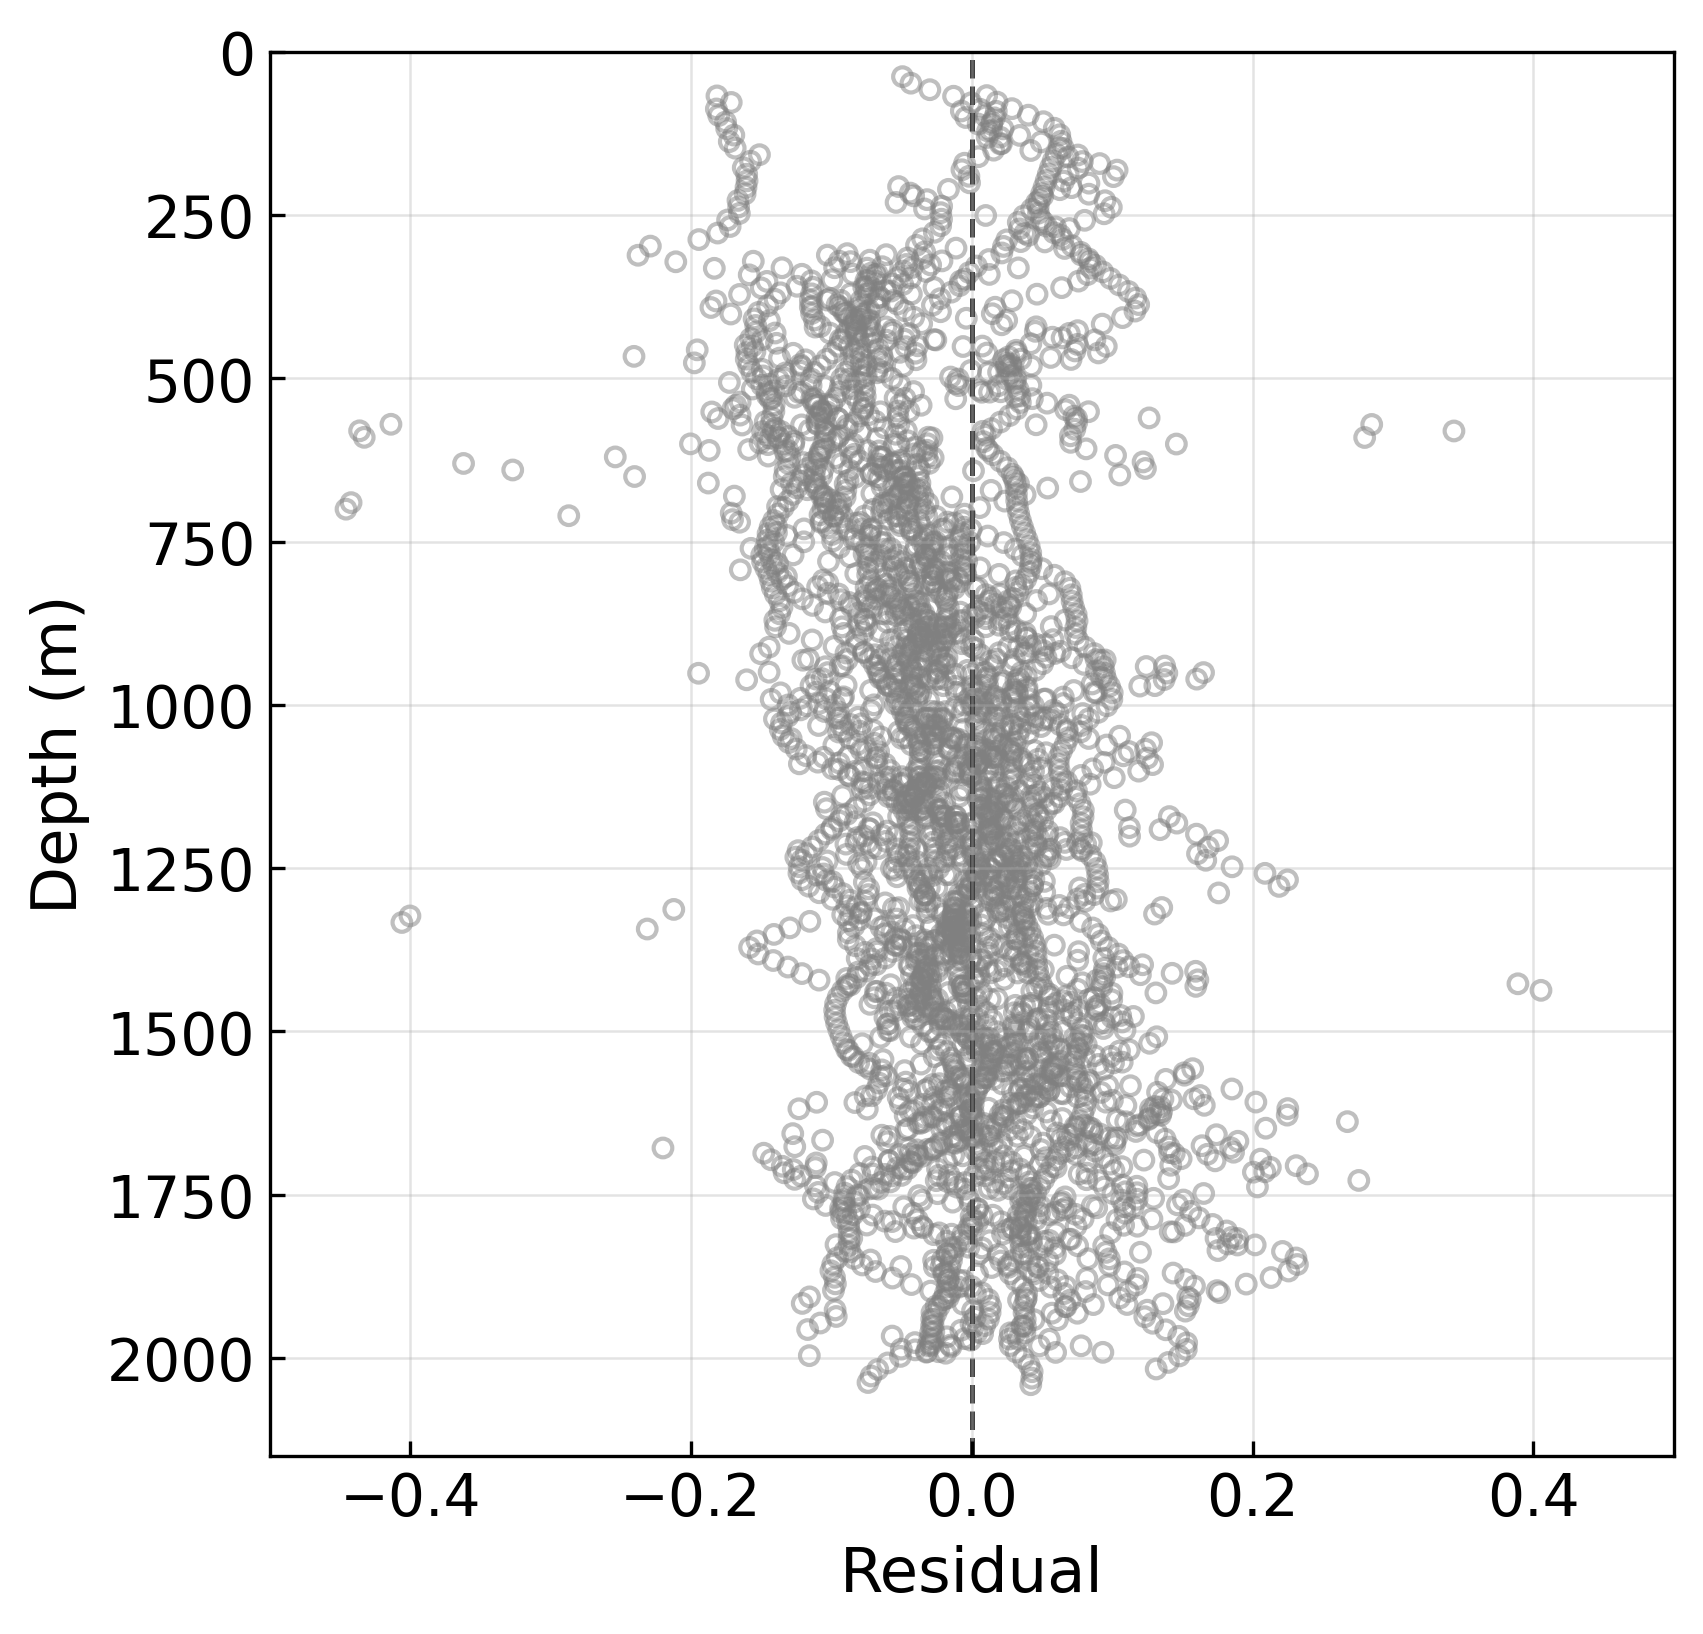

In [11]:
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams["mathtext.rm"] = "Arial"
plt.rcParams["mathtext.it"] = "Arial:italic"
plt.rcParams["mathtext.bf"] = "Arial:bold"
plt.rcParams["font.size"] = 14

fig, ax = plt.subplots(1, 1, figsize=(6, 6), dpi=300)

ax.scatter(
    df_sonic['diff'], df_sonic['vs_depth'],
    s=20,
    facecolors="none",
    edgecolors="gray",
    linewidths=1,
    alpha=0.5,
    label="_nolegend_"
)

ax.axvline(
    0,
    color="0.25",
    linestyle="--",
    linewidth=1.2,
    zorder=1
)


ax.set_xlim(-0.5, 0.5)
ax.set_ylim(2150, 0)

ax.set_xlabel("Residual", fontsize=15)
ax.set_ylabel("Depth (m)", fontsize=15)

ax.set_box_aspect(1)

ax.grid(
    True,
    linestyle="-",
    linewidth=0.6,
    alpha=0.35
)

fig.subplots_adjust(
    left=0.18,
    right=0.96,
    bottom=0.16,
    top=0.96
)

fig.savefig(
    dir_fig + "vs_log_cleaned.png",
    format="png",
    dpi=300
)

plt.show()

In [31]:
df_avg_combined = pd.read_csv(dir_out+'Preprocessing_log/vs_data_combined_full.txt', encoding='utf-8')
df_avg_combined

,DEPTH_m,velocity_mps,X,Y,source_file,TVDSS,velocity
0,43.5280,1713.535764,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,43.528000,1702.435158
1,53.5280,1756.154846,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,53.528000,1723.341882
2,63.5280,1738.138676,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,63.528000,1750.140249
3,73.5280,1699.290684,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,73.528000,1779.210020
4,83.5280,1748.027201,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,83.528000,1806.930958
...,...,...,...,...,...,...,...
3943,2136.3772,3271.509531,387298.0938,3767711.984,tuo_2,2053.377197,3271.900954
3944,2146.3772,3371.830612,387298.0938,3767711.984,tuo_2,2063.377197,3371.866645
3945,2156.3772,3429.633928,387298.0938,3767711.984,tuo_2,2073.377197,3429.285539
3946,2166.3772,3412.144009,387298.0938,3767711.984,tuo_2,2083.377197,3411.818368


In [32]:
df_combined_raw = pd.read_csv(dir_out+'Preprocessing_log/vs_data_combined_raw.txt', encoding='utf-8')
df_combined_raw

,source_file,X,Y,DEPTH,ITT_DIG,TVDSS,velocity_mps,DEPTH_m
0,sobudd_1,388094.4688,3764796.922,1400.0,157.298000,354.720001,1937.723302,426.7200
1,sobudd_1,388094.4688,3764796.922,1400.5,157.101000,354.872406,1940.153150,426.8724
2,sobudd_1,388094.4688,3764796.922,1401.0,156.903000,355.024811,1942.601480,427.0248
3,sobudd_1,388094.4688,3764796.922,1401.5,156.509000,355.177216,1947.491838,427.1772
4,sobudd_1,388094.4688,3764796.922,1402.0,156.114000,355.329620,1952.419386,427.3296
...,...,...,...,...,...,...,...,...
262129,HVD_CVMH_uolt_1r.las,382795.5620,3761977.670,9487.5,92.772003,2836.790040,3285.473952,2891.7900
262130,HVD_CVMH_uolt_1r.las,382795.5620,3761977.670,9488.0,92.573998,2836.942380,3292.501223,2891.9424
262131,HVD_CVMH_uolt_1r.las,382795.5620,3761977.670,9488.5,92.573998,2837.094970,3292.501223,2892.0948
262132,HVD_CVMH_uolt_1r.las,382795.5620,3761977.670,9489.0,92.376000,2837.247310,3299.558345,2892.2472


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

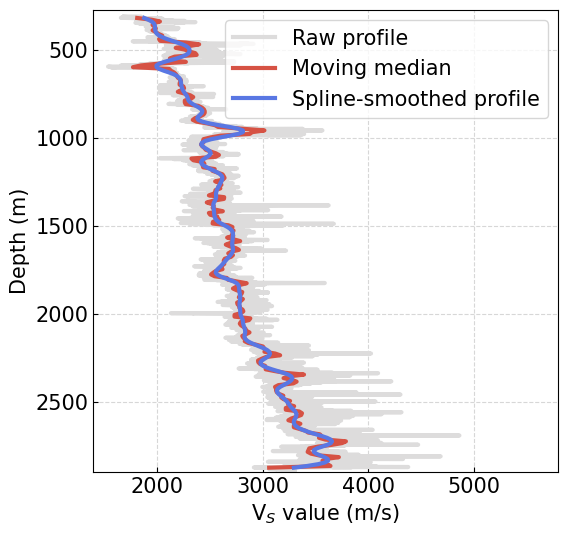

In [33]:
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams["mathtext.rm"] = "Arial"
plt.rcParams["mathtext.it"] = "Arial:italic"
plt.rcParams["mathtext.bf"] = "Arial:bold"

subset = df_avg_combined[df_avg_combined['source_file'] == 'HVD_CVMH_uolt_1r.las']
subset2 = df_combined_raw[df_combined_raw['source_file'] == 'HVD_CVMH_uolt_1r.las']


fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.plot(subset2['velocity_mps'], subset2['DEPTH_m'], color=gray_color, linewidth=3, label='Raw profile')
ax.plot(subset['velocity_mps'], subset['DEPTH_m'], color=red_color, linewidth=3, label='Moving median')
ax.plot(subset['velocity'], subset['DEPTH_m'], color=blue_color, linewidth=3, label='Spline-smoothed profile')

ax.set( xlim=(1400, 5800), ylim=(270, 2900),)

ax.set_xlabel(r"$\mathrm{V}_S$ value (m/s)", fontsize=15)
ax.set_ylabel("Depth (m)", fontsize=15)
ax.tick_params(labelsize =15)


ax.invert_yaxis()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

ax.legend(fontsize=15)
fig.savefig(dir_fig+'vs_log_cleaned1.png', format='png', dpi=300)

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

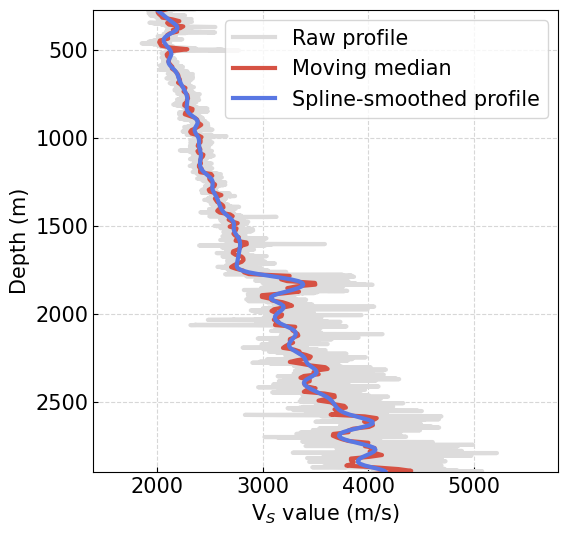

In [34]:
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams["mathtext.rm"] = "Arial"
plt.rcParams["mathtext.it"] = "Arial:italic"
plt.rcParams["mathtext.bf"] = "Arial:bold"

subset = df_avg_combined[df_avg_combined['source_file'] == 'HVD_CVMH_soccom_1.las']
subset2 = df_combined_raw[df_combined_raw['source_file'] == 'HVD_CVMH_soccom_1.las']


fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.plot(subset2['velocity_mps'], subset2['DEPTH_m'], color=gray_color, linewidth=3, label='Raw profile')
ax.plot(subset['velocity_mps'], subset['DEPTH_m'], color=red_color, linewidth=3, label='Moving median')
ax.plot(subset['velocity'], subset['DEPTH_m'], color=blue_color, linewidth=3, label='Spline-smoothed profile')

ax.set( xlim=(1400, 5800), ylim=(270, 2900),)


ax.set_xlabel(r"$\mathrm{V}_S$ value (m/s)", fontsize=15)
ax.set_ylabel("Depth (m)", fontsize=15)
ax.tick_params(labelsize =15)

ax.invert_yaxis()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

ax.legend(fontsize = 15)
fig.savefig(dir_fig+'vs_log_cleaned2.png', format='png', dpi=300)

In [13]:
df_hyper1 = pd.read_csv(dir_out+'Hyperparameters/vs_data_hyper_step1.txt', encoding='utf-8')
df_hyper1 = df_hyper1[df_hyper1['iteration']< 1501]
df_hyper1['stat_z'] = df_hyper1['stat_z'] * 73.33
df_hyper1['stat_z2.5'] = df_hyper1['stat_z2.5'] * 1294.33
df_hyper1['stat_elevation'] = df_hyper1['stat_elevation'] * 189.68
df_hyper1

,iteration,stat_z,stat_z2.5,stat_elevation,stat_scale,stat_scale_id,noise,loss,sum
0,1,68.780653,1278.027008,187.290829,0.035482,0.035482,0.198016,0.392288,0.268980
1,2,64.404092,1273.472480,184.973958,0.036184,0.036179,0.196168,0.396984,0.268531
2,3,60.199156,1271.525459,182.661650,0.036902,0.036894,0.194354,0.392369,0.268150
3,4,56.181954,1268.631078,180.347981,0.037634,0.037624,0.192575,0.387861,0.267832
4,5,52.374892,1263.073095,178.033591,0.038377,0.038364,0.190829,0.383564,0.267571
...,...,...,...,...,...,...,...,...,...
1495,1496,32.085210,12.138497,9.006374,0.047879,0.120844,0.100257,0.023757,0.268980
1496,1497,32.085173,12.138058,9.005619,0.047880,0.120843,0.100257,0.023757,0.268980
1497,1498,32.085015,12.137534,9.004854,0.047881,0.120843,0.100257,0.023754,0.268980
1498,1499,32.084736,12.137020,9.004088,0.047882,0.120842,0.100256,0.023753,0.268980


In [14]:
df_hyper2 = pd.read_csv(dir_out+'Hyperparameters/vs_data_hyper_step2.txt', encoding='utf-8')
df_hyper2

,iteration,matern_elevation,matern_xy,outputscale_shape,stat_z,stat_z2.5,stat_elevation,stat_scale_id,stat_scale,noise,loss
0,1,0.227451,0.794356,0.644436,0.437842,0.009327,0.044404,0.120371,0.048511,0.517958,0.744945
1,2,0.245410,0.820800,0.621101,0.437842,0.009327,0.044404,0.120371,0.048511,0.442313,0.675284
2,3,0.264575,0.847749,0.598476,0.437842,0.009327,0.044404,0.120371,0.048511,0.375764,0.604016
3,4,0.284979,0.875150,0.576586,0.437842,0.009327,0.044404,0.120371,0.048511,0.317744,0.531559
4,5,0.306648,0.902940,0.555454,0.437842,0.009327,0.044404,0.120371,0.048511,0.267594,0.458407
...,...,...,...,...,...,...,...,...,...,...,...
1495,1496,0.086642,0.050223,0.026150,0.437842,0.009327,0.044404,0.120371,0.048511,0.022679,-0.266914
1496,1497,0.086641,0.050223,0.026150,0.437842,0.009327,0.044404,0.120371,0.048511,0.022679,-0.266912
1497,1498,0.086641,0.050222,0.026150,0.437842,0.009327,0.044404,0.120371,0.048511,0.022679,-0.266918
1498,1499,0.086640,0.050222,0.026151,0.437842,0.009327,0.044404,0.120371,0.048511,0.022679,-0.266916


In [15]:
df_hyper2['matern_elevation'] = df_hyper2['matern_elevation'] * 297.95
df_hyper2['matern_xy'] = df_hyper2['matern_xy'] * 32549
df_hyper2['stat_z'] = df_hyper2['stat_z'] * 73.33
df_hyper2['stat_z2.5'] = df_hyper2['stat_z2.5'] * 1294.33
df_hyper2['stat_elevation'] = df_hyper2['stat_elevation'] * 189.68
df_hyper2

,iteration,matern_elevation,matern_xy,outputscale_shape,stat_z,stat_z2.5,stat_elevation,stat_scale_id,stat_scale,noise,loss
0,1,67.769062,25855.489190,0.644436,32.106946,12.071645,8.422597,0.120371,0.048511,0.517958,0.744945
1,2,73.119969,26716.225228,0.621101,32.106946,12.071645,8.422597,0.120371,0.048511,0.442313,0.675284
2,3,78.830005,27593.385913,0.598476,32.106946,12.071645,8.422597,0.120371,0.048511,0.375764,0.604016
3,4,84.909583,28485.267861,0.576586,32.106946,12.071645,8.422597,0.120371,0.048511,0.317744,0.531559
4,5,91.365864,29389.795195,0.555454,32.106946,12.071645,8.422597,0.120371,0.048511,0.267594,0.458407
...,...,...,...,...,...,...,...,...,...,...,...
1495,1496,25.814850,1634.706862,0.026150,32.106946,12.071645,8.422597,0.120371,0.048511,0.022679,-0.266914
1496,1497,25.814619,1634.698010,0.026150,32.106946,12.071645,8.422597,0.120371,0.048511,0.022679,-0.266912
1497,1498,25.814547,1634.689038,0.026150,32.106946,12.071645,8.422597,0.120371,0.048511,0.022679,-0.266918
1498,1499,25.814505,1634.680065,0.026151,32.106946,12.071645,8.422597,0.120371,0.048511,0.022679,-0.266916


In [16]:
df_points_1 = pd.read_csv(dir_out+'Point_input/df_ucvm_1.txt', encoding='utf-8')
df_points_1

,long,lat,vs_depth,surf_elevation,vs30,cvm,cvm_vp,cvm_vs,cvm_dens,gtl,...,distance,Z_2.5,basin_idnum,predict_diff,predict_vs,predict_diff_low,predict_vs_low,predict_diff_upper,predict_vs_upper,shi
0,-117.8869,33.7068,0.0,11.451,227.252,cvms5,1579.720,871.215,2041.549,none,...,0.0,3680,1,-1.931121,126.313617,-2.406837,78.496291,-1.455404,203.259666,176.411162
1,-117.8869,33.7068,1.0,11.451,227.252,cvms5,1580.827,871.814,2041.858,none,...,0.0,3680,1,-1.878540,133.224546,-2.351413,83.026804,-1.405668,213.771682,176.411162
2,-117.8869,33.7068,2.0,11.451,227.252,cvms5,1581.933,872.413,2042.166,none,...,0.0,3680,1,-1.826517,140.435199,-2.297834,87.656776,-1.355200,224.991677,176.411162
3,-117.8869,33.7068,3.0,11.451,227.252,cvms5,1583.040,873.013,2042.474,none,...,0.0,3680,1,-1.775252,147.923949,-2.245321,92.446423,-1.305183,236.693795,179.885775
4,-117.8869,33.7068,4.0,11.451,227.252,cvms5,1584.146,873.612,2042.782,none,...,0.0,3680,1,-1.724929,155.665139,-2.194333,97.349104,-1.255526,248.914826,186.620533
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,-117.8869,33.7068,66.0,11.451,227.252,cvms5,1652.749,910.760,2061.418,none,...,0.0,3680,1,-0.577761,511.075802,-1.101075,302.839914,-0.054448,862.496863,423.229818
67,-117.8869,33.7068,67.0,11.451,227.252,cvms5,1653.856,911.360,2061.712,none,...,0.0,3680,1,-0.574206,513.234157,-1.100166,303.315114,-0.048246,868.434469,425.881395
68,-117.8869,33.7068,68.0,11.451,227.252,cvms5,1654.962,911.959,2062.005,none,...,0.0,3680,1,-0.570693,515.378601,-1.099327,303.769113,-0.042059,874.397991,428.514782
69,-117.8869,33.7068,69.0,11.451,227.252,cvms5,1656.069,912.558,2062.298,none,...,0.0,3680,1,-0.567190,517.527218,-1.098583,304.194959,-0.035796,880.469623,431.130336


In [17]:
df_points_3 = pd.read_csv(dir_out+'Point_input/df_ucvm_3.txt', encoding='utf-8')
df_points_3

,long,lat,vs_depth,surf_elevation,vs30,cvm,cvm_vp,cvm_vs,cvm_dens,gtl,...,distance,Z_2.5,basin_idnum,predict_diff,predict_vs,predict_diff_low,predict_vs_low,predict_diff_upper,predict_vs_upper,shi
0,-117.2917,34.0935,0.0,305.389,296.381,cvms5,1615.518,893.166,2052.700,none,...,0.0,1820,4,-1.493627,200.566422,-2.110589,108.221896,-0.876665,371.707493,202.861169
1,-117.2917,34.0935,1.0,305.389,296.381,cvms5,1616.472,893.633,2052.934,none,...,0.0,1820,4,-1.448484,209.937707,-2.065077,113.320246,-0.831891,388.931745,202.861169
2,-117.2917,34.0935,2.0,305.389,296.381,cvms5,1617.427,894.100,2053.168,none,...,0.0,1820,4,-1.403209,219.776040,-2.019540,118.661784,-0.786877,407.051925,202.861169
3,-117.2917,34.0935,3.0,305.389,296.381,cvms5,1618.381,894.567,2053.401,none,...,0.0,1820,4,-1.358019,230.055562,-1.974223,124.227785,-0.741815,426.036427,210.044828
4,-117.2917,34.0935,4.0,305.389,296.381,cvms5,1619.336,895.034,2053.635,none,...,0.0,1820,4,-1.313126,240.744327,-1.929262,130.008439,-0.696990,445.800530,223.201180
5,-117.2917,34.0935,5.0,305.389,296.381,cvms5,1620.290,895.501,2053.868,none,...,0.0,1820,4,-1.268731,251.804238,-1.884837,135.985223,-0.652626,466.266646,235.074621
6,-117.2917,34.0935,6.0,305.389,296.381,cvms5,1621.245,895.968,2054.102,none,...,0.0,1820,4,-1.225024,263.191165,-1.841115,142.136761,-0.608933,487.344648,245.942559
7,-117.2917,34.0935,7.0,305.389,296.381,cvms5,1622.199,896.435,2054.335,none,...,0.0,1820,4,-1.182181,274.855248,-1.798273,148.435867,-0.566090,508.943081,255.997047
8,-117.2917,34.0935,8.0,305.389,296.381,cvms5,1623.154,896.902,2054.568,none,...,0.0,1820,4,-1.140366,286.741385,-1.756413,154.861905,-0.524319,530.928648,265.377241
9,-117.2917,34.0935,9.0,305.389,296.381,cvms5,1624.108,897.370,2054.801,none,...,0.0,1820,4,-1.099726,298.790253,-1.715780,161.368152,-0.483673,553.241853,274.187598


In [18]:
df_close1 = df_measure[df_measure['velocity_metadata_id'] == 447]
df_close1

,velocity_metadata_id,vs_depth,vs_value,vs_top_depth,vs_bottom_depth,test_id,velocity_name,velocity_method,velocity_date,velocity_quality,...,terrain_class,site_easting,site_northing,test_easting,test_northing,vs_model,surf_elevation,Z_2.5,diff,basin_idnum
8920,447,0.50,99.0,0.0,1.0,411,CISAN,MASW,NaN,NaN,...,16,417777.664087,3.729956e+06,417777.664087,3.729956e+06,872.394,11.444,3680.0,-2.176121,1
8921,447,1.75,133.0,1.0,2.5,411,CISAN,MASW,NaN,NaN,...,16,417777.664087,3.729956e+06,417777.664087,3.729956e+06,873.139,11.444,3680.0,-1.881746,1
8922,447,3.75,138.0,2.5,5.0,411,CISAN,MASW,NaN,NaN,...,16,417777.664087,3.729956e+06,417777.664087,3.729956e+06,874.330,11.444,3680.0,-1.846204,1
8923,447,7.00,171.0,5.0,9.0,411,CISAN,MASW,NaN,NaN,...,16,417777.664087,3.729956e+06,417777.664087,3.729956e+06,876.265,11.444,3680.0,-1.634005,1
8924,447,12.00,245.0,9.0,15.0,411,CISAN,MASW,NaN,NaN,...,16,417777.664087,3.729956e+06,417777.664087,3.729956e+06,879.243,11.444,3680.0,-1.277803,1
8925,447,19.50,301.0,15.0,24.0,411,CISAN,MASW,NaN,NaN,...,16,417777.664087,3.729956e+06,417777.664087,3.729956e+06,883.710,11.444,3680.0,-1.077019,1
8926,447,30.00,340.0,24.0,36.0,411,CISAN,MASW,NaN,NaN,...,16,417777.664087,3.729956e+06,417777.664087,3.729956e+06,889.963,11.444,3680.0,-0.962234,1
8927,447,43.50,407.0,36.0,51.0,411,CISAN,MASW,NaN,NaN,...,16,417777.664087,3.729956e+06,417777.664087,3.729956e+06,898.004,11.444,3680.0,-0.791361,1
8928,447,60.50,477.0,51.0,70.0,411,CISAN,MASW,NaN,NaN,...,16,417777.664087,3.729956e+06,417777.664087,3.729956e+06,908.128,11.444,3680.0,-0.643869,1


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Ari

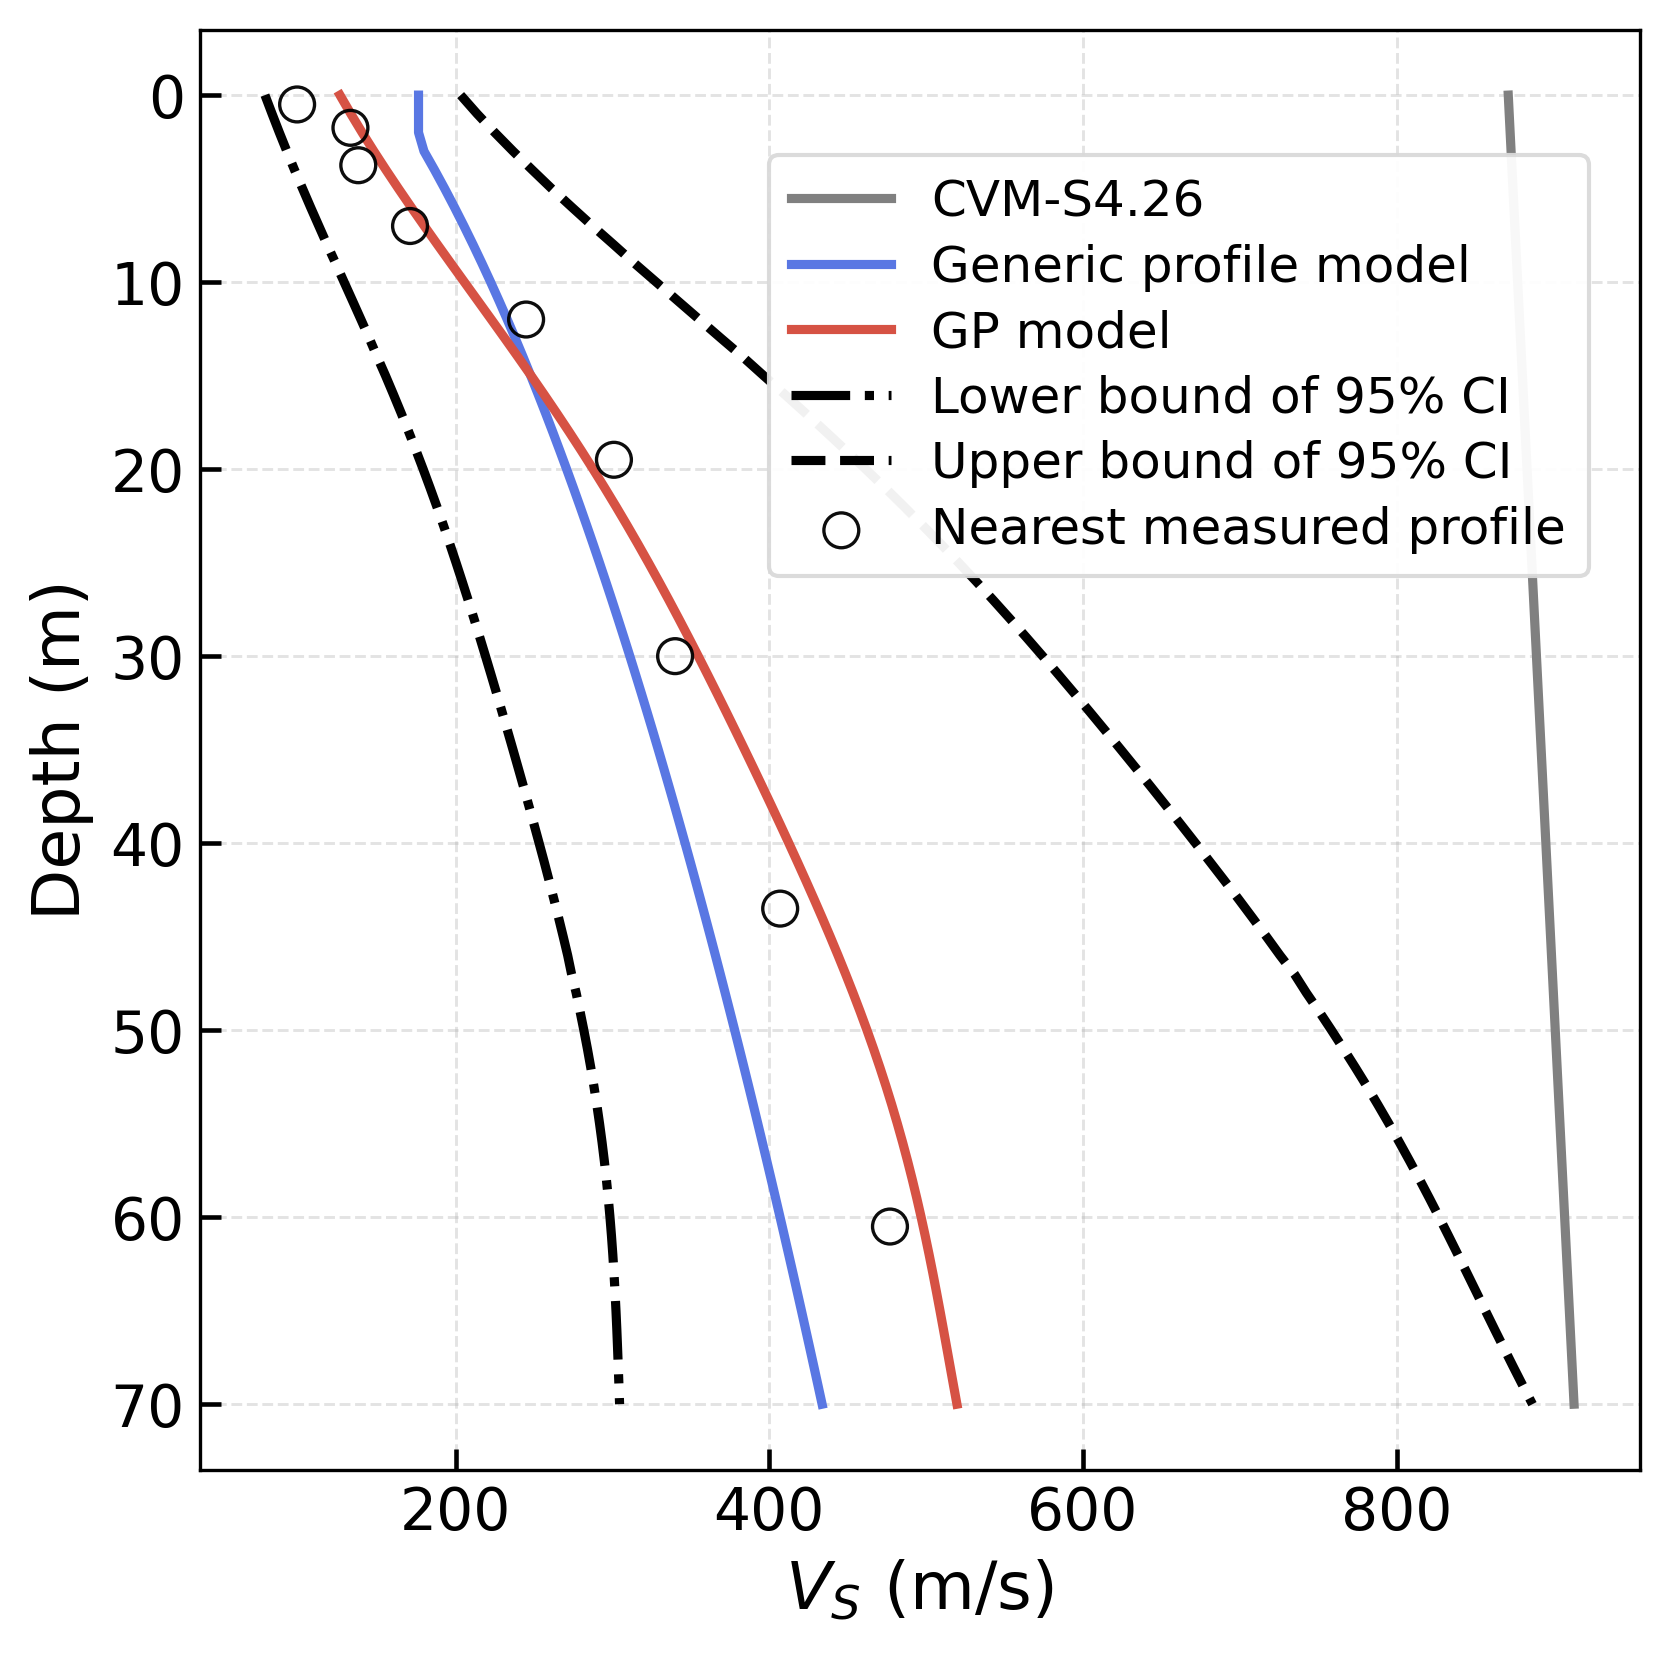

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

In [19]:
fig, ax = plt.subplots(figsize=(6, 6), dpi=300)

ax.plot(
    df_points_1['cvm_vs'], df_points_1['vs_depth'],
    color='gray', lw=2.2, label="CVM-S4.26"
)

ax.plot(
    df_points_1['shi'], df_points_1['vs_depth'],
    color=blue_color, lw=2.2, label="Generic profile model"
)

ax.plot(
    df_points_1['predict_vs'], df_points_1['vs_depth'],
    color=red_color, lw=2.2, label="GP model"
)

ax.plot(
    df_points_1['predict_vs_low'], df_points_1['vs_depth'],
    color='black', lw=2.2,
    label="Lower bound of 95% CI",
    linestyle="-."
)

ax.plot(
    df_points_1['predict_vs_upper'], df_points_1['vs_depth'],
    color='black', lw=2.2,
    label="Upper bound of 95% CI",
    linestyle="--"
)

ax.scatter(
    df_close1['vs_value'], df_close1['vs_depth'],
    s=70,
    facecolors="none",
    edgecolors="black",
    linewidth=0.8,
    alpha=0.95,
    label="Nearest measured profile",
    zorder=5
)

ax.invert_yaxis()

ax.set_xlabel(r"$V_S$ (m/s)", fontsize=16)
ax.set_ylabel("Depth (m)", fontsize=16)

ax.grid(
    True, which="major",
    linestyle="--", linewidth=0.7, alpha=0.35
)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=14,
    length=5,
    width=1.1
)

ax.set_box_aspect(1)

leg = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.68, 0.93),
    fontsize=12,
    frameon=True,
    edgecolor="0.85",
    handlelength=2.0,
    labelspacing=0.35,
    borderpad=0.45
)

leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(0.95)

fig.subplots_adjust(
    left=0.16,
    right=0.96,
    bottom=0.14,
    top=0.96
)

plt.show()
fig.savefig(dir_fig+'point1.png', format='png', dpi=300, bbox_inches = None)

In [20]:
df_close2 = df_measure[df_measure['velocity_metadata_id'] == 1422]
df_close2

,velocity_metadata_id,vs_depth,vs_value,vs_top_depth,vs_bottom_depth,test_id,velocity_name,velocity_method,velocity_date,velocity_quality,...,terrain_class,site_easting,site_northing,test_easting,test_northing,vs_model,surf_elevation,Z_2.5,diff,basin_idnum
9691,1422,1.15,177.0,0.0,2.3,1363,CE.23780,MASW,2017-05-11,NaN,...,8,473507.658903,3.772882e+06,473507.839618,3.772946e+06,900.796,307.781,1660.0,-1.627129,4
9692,1422,4.00,210.0,2.3,5.7,1363,CE.23780,MASW,2017-05-11,NaN,...,8,473507.658903,3.772882e+06,473507.839618,3.772946e+06,902.151,307.781,1660.0,-1.457674,4
9693,1422,7.20,329.0,5.7,8.7,1363,CE.23780,MASW,2017-05-11,NaN,...,8,473507.658903,3.772882e+06,473507.839618,3.772946e+06,903.673,307.781,1660.0,-1.010410,4
9694,1422,9.95,265.0,8.7,11.2,1363,CE.23780,MASW,2017-05-11,NaN,...,8,473507.658903,3.772882e+06,473507.839618,3.772946e+06,904.981,307.781,1660.0,-1.228184,4
9695,1422,11.70,381.0,11.2,12.2,1363,CE.23780,MASW,2017-05-11,NaN,...,8,473507.658903,3.772882e+06,473507.839618,3.772946e+06,905.814,307.781,1660.0,-0.866035,4
9696,1422,14.60,342.0,12.2,17.0,1363,CE.23780,MASW,2017-05-11,NaN,...,8,473507.658903,3.772882e+06,473507.839618,3.772946e+06,907.193,307.781,1660.0,-0.975544,4
9697,1422,20.10,371.0,17.0,23.2,1363,CE.23780,MASW,2017-05-11,NaN,...,8,473507.658903,3.772882e+06,473507.839618,3.772946e+06,909.809,307.781,1660.0,-0.897033,4
9698,1422,26.05,610.0,23.2,28.9,1363,CE.23780,MASW,2017-05-11,NaN,...,8,473507.658903,3.772882e+06,473507.839618,3.772946e+06,912.639,307.781,1660.0,-0.402881,4
9699,1422,29.70,310.0,28.9,30.5,1363,CE.23780,MASW,2017-05-11,NaN,...,8,473507.658903,3.772882e+06,473507.839618,3.772946e+06,914.375,307.781,1660.0,-1.081668,4
9700,1422,32.60,515.0,30.5,34.7,1363,CE.23780,MASW,2017-05-11,NaN,...,8,473507.658903,3.772882e+06,473507.839618,3.772946e+06,915.754,307.781,1660.0,-0.575581,4


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

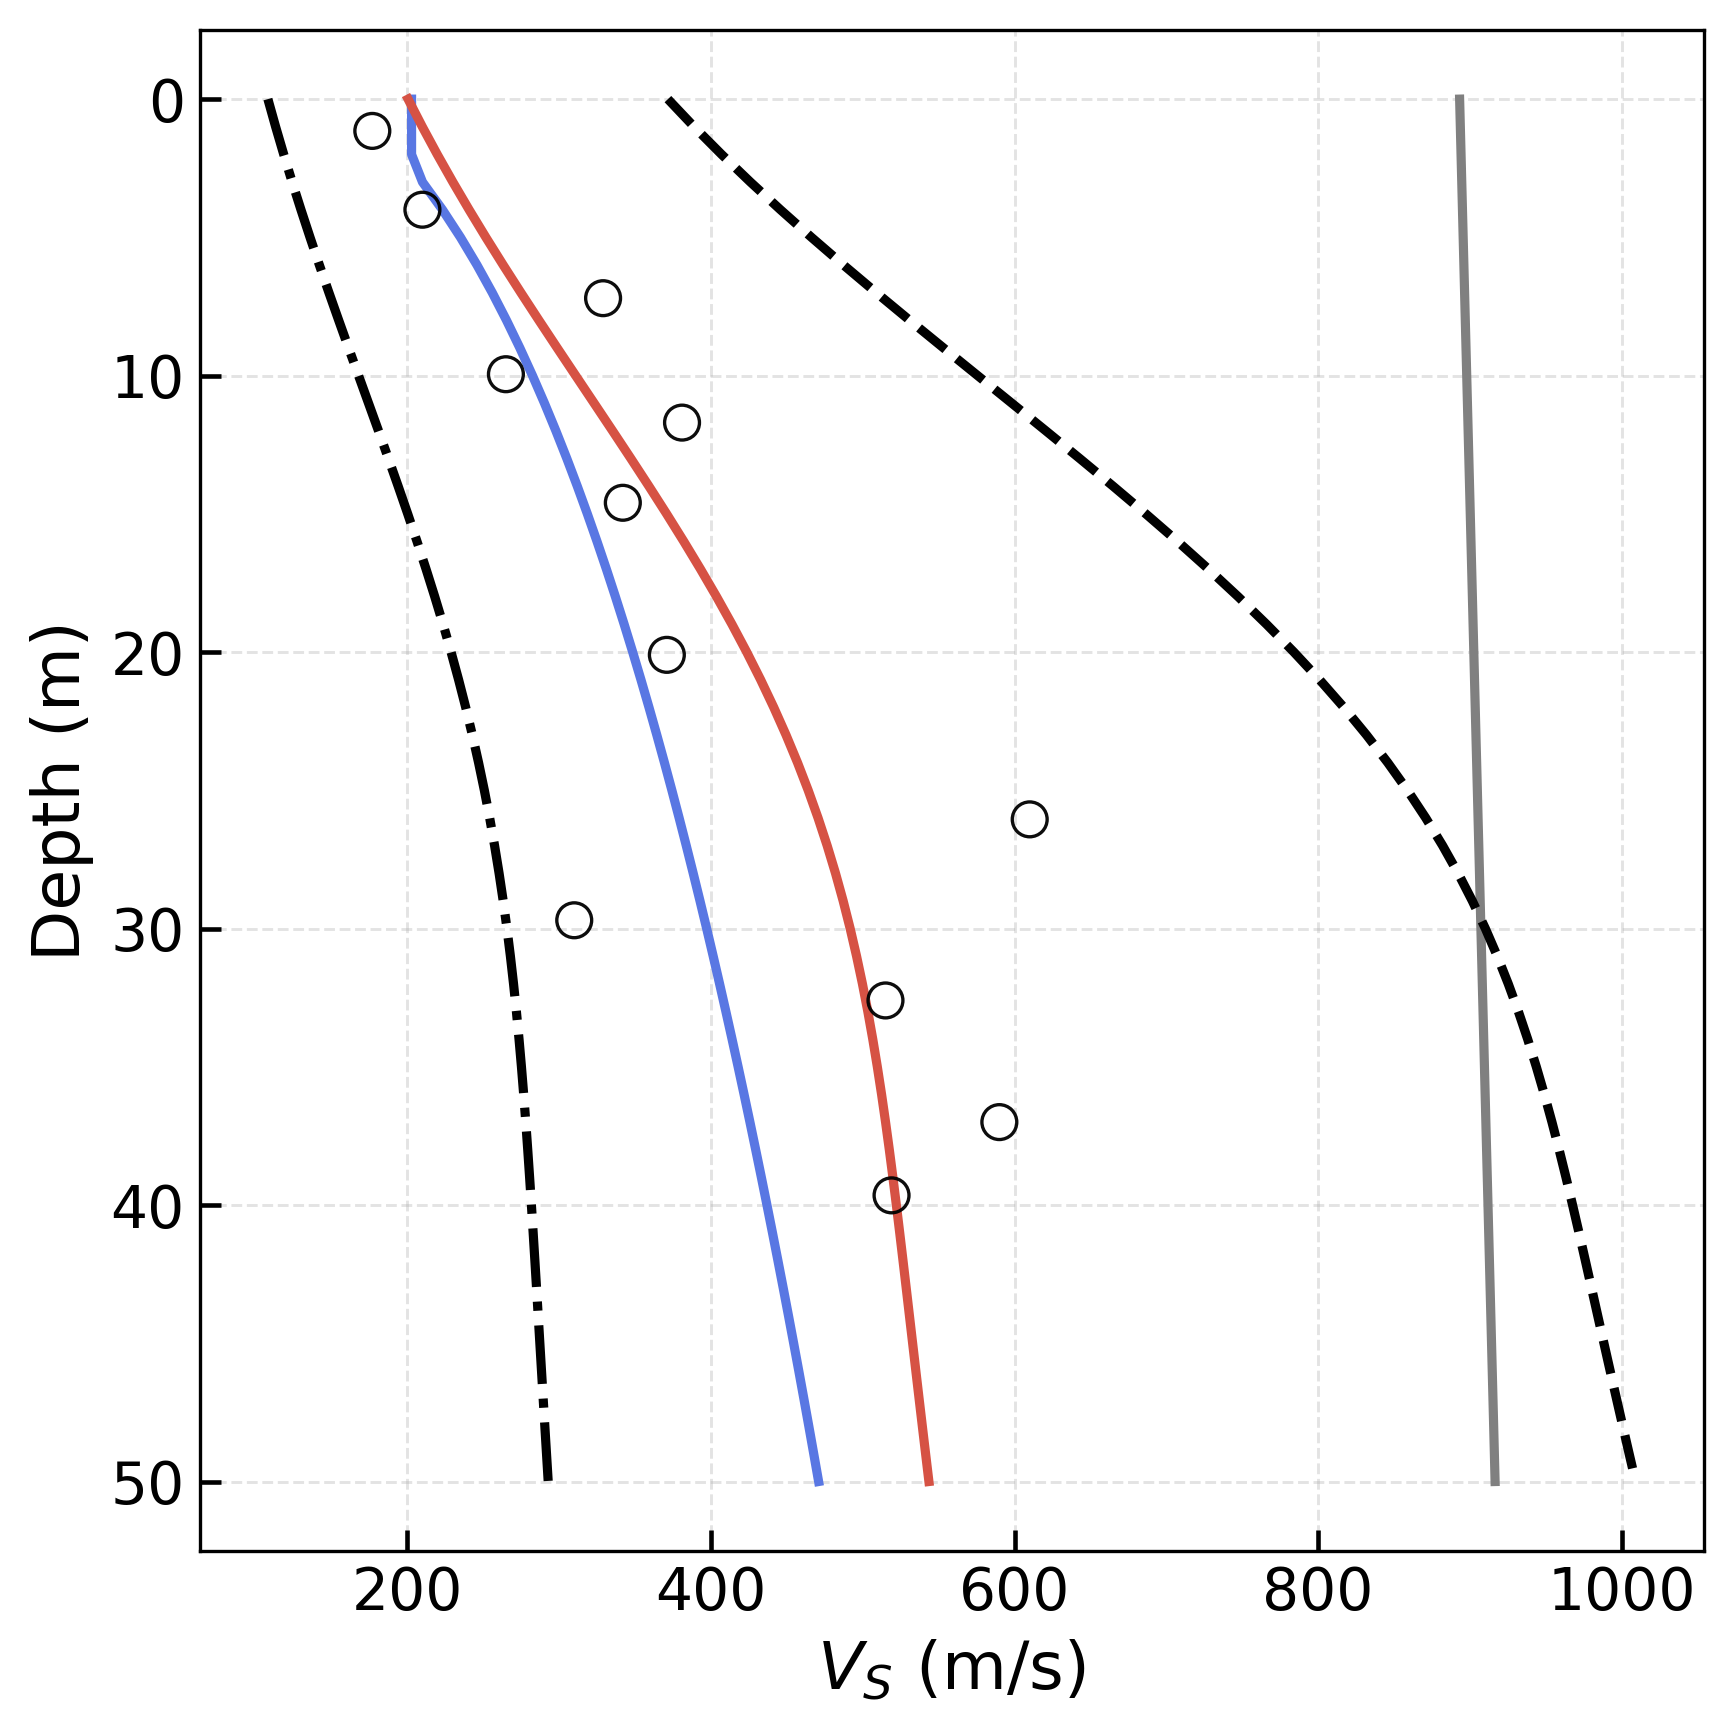

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

In [21]:


fig, ax = plt.subplots(figsize=(6, 6), dpi=300)


ax.plot(
    df_points_3['cvm_vs'], df_points_3['vs_depth'],
    color='gray', lw=2.2
)

ax.plot(
    df_points_3['shi'], df_points_3['vs_depth'],
    color=blue_color, lw=2.2
)

ax.plot(
    df_points_3['predict_vs'], df_points_3['vs_depth'],
    color=red_color, lw=2.2
)

ax.plot(
    df_points_3['predict_vs_low'], df_points_3['vs_depth'],
    color='black', lw=2.2,linestyle="-.",
)

ax.plot(
    df_points_3['predict_vs_upper'], df_points_3['vs_depth'],
    color='black', lw=2.2,linestyle="--",
)

ax.scatter(
    df_close2['vs_value'], df_close2['vs_depth'],
    s=70, color="black",
    linewidth=0.8, alpha=0.95,
    facecolors="none",
    edgecolors="black",
    zorder=5
)

ax.invert_yaxis()
ax.set_xlabel(r"$V_S$ (m/s)", fontsize=16)
ax.set_ylabel("Depth (m)", fontsize=16)

ax.grid(
    True, which="major",
    linestyle="--", linewidth=0.7, alpha=0.35
)


ax.tick_params(axis="both", which="major", labelsize=14, length=5, width=1.1)

'''
leg = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.73, 0.93),
    fontsize=12,
    frameon=True,
    edgecolor="0.85",
    handlelength=2.0,
    labelspacing=0.35,
    borderpad=0.45
)

leg.get_frame().set_edgecolor("0.85")
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(0.95)
'''

fig.subplots_adjust(
    left=0.16,
    right=0.96,
    bottom=0.14,
    top=0.96
)

plt.tight_layout()
plt.show()

fig.savefig(dir_fig+'point2.png', format='png', dpi=300, bbox_inches = None)

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

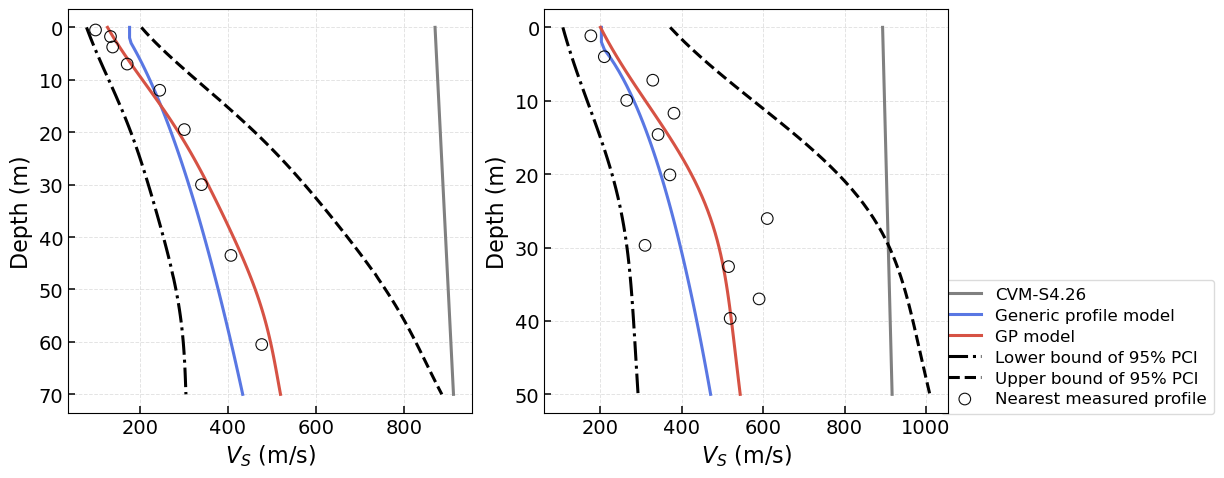

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

In [22]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 10),
    sharex=False,
    sharey=False
)

ax1, ax2 = axes

l1 = ax1.plot(
    df_points_1['cvm_vs'], df_points_1['vs_depth'],
    color='gray', lw=2.2, label="CVM-S4.26"
)

l2 = ax1.plot(
    df_points_1['shi'], df_points_1['vs_depth'],
    color=blue_color, lw=2.2, label="Generic profile model"
)

l3 = ax1.plot(
    df_points_1['predict_vs'], df_points_1['vs_depth'],
    color=red_color, lw=2.2, label="GP model"
)

l4 = ax1.plot(
    df_points_1['predict_vs_low'], df_points_1['vs_depth'],
    color='black', lw=2.2,
    label="Lower bound of 95% PCI",
    linestyle="-."
)

l5 = ax1.plot(
    df_points_1['predict_vs_upper'], df_points_1['vs_depth'],
    color='black', lw=2.2,
    label="Upper bound of 95% PCI",
    linestyle="--"
)

l6 = ax1.scatter(
    df_close1['vs_value'], df_close1['vs_depth'],
    s=70,
    facecolors="none",
    edgecolors="black",
    linewidth=0.8,
    alpha=0.95,
    label="Nearest measured profile",
    zorder=5
)

ax1.invert_yaxis()

ax1.set_xlabel(r"$V_S$ (m/s)", fontsize=16)
ax1.set_ylabel("Depth (m)", fontsize=16)

ax1.grid(
    True, which="major",
    linestyle="--", linewidth=0.7, alpha=0.35
)

ax1.tick_params(
    axis="both",
    which="major",
    labelsize=14,
    length=5,
    width=1.1
)

ax1.set_box_aspect(1)


leg = ax1.legend(
    loc="upper center",
    bbox_to_anchor=(2.5, 0.35),
    fontsize=12,
    frameon=True,
    edgecolor="0.85",
    handlelength=2.0,
    labelspacing=0.35,
    borderpad=0.45
)

leg.get_frame().set_edgecolor("0.85")
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(0.95)



ax2.plot(
    df_points_3['cvm_vs'], df_points_3['vs_depth'],
    color='gray', lw=2.2
)

ax2.plot(
    df_points_3['shi'], df_points_3['vs_depth'],
    color=blue_color, lw=2.2
)

ax2.plot(
    df_points_3['predict_vs'], df_points_3['vs_depth'],
    color=red_color, lw=2.2
)

ax2.plot(
    df_points_3['predict_vs_low'], df_points_3['vs_depth'],
    color='black', lw=2.2,linestyle="-.",
)

ax2.plot(
    df_points_3['predict_vs_upper'], df_points_3['vs_depth'],
    color='black', lw=2.2,linestyle="--",
)

ax2.scatter(
    df_close2['vs_value'], df_close2['vs_depth'],
    s=70, color="black",
    linewidth=0.8, alpha=0.95,
    facecolors="none",
    edgecolors="black",
    zorder=5
)

ax2.invert_yaxis()

ax2.set_xlabel(r"$V_S$ (m/s)", fontsize=16)
ax2.set_ylabel("Depth (m)", fontsize=16)

ax2.grid(
    True, which="major",
    linestyle="--", linewidth=0.7, alpha=0.35
)

ax2.tick_params(
    axis="both",
    which="major",
    labelsize=14,
    length=5,
    width=1.1
)

ax2.set_box_aspect(1)

fig.subplots_adjust(
    left=0.10,
    right=0.98,
    bottom=0.12,
    top=0.88,
    wspace=0.18
)

plt.show()

fig.savefig(dir_fig+'points.png', format='png', dpi=300)

In [24]:
df_residual = pd.read_csv(dir_out+'Residual/vs_measure.txt', encoding='utf-8')
df_residual

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum,vs_model,vs_value,predict_diff,predict_vs,residual
0,1.00,2380.0,251.052,352134.046903,3.786794e+06,-1.800524,610,295.692,2,938.187,155.0,-1.738185,164.970127,-0.062339
1,2.00,2380.0,251.052,352134.046903,3.786794e+06,-1.707914,610,295.692,2,939.068,170.2,-1.664825,177.694041,-0.043089
2,3.00,2380.0,251.052,352134.046903,3.786794e+06,-1.565163,610,295.692,2,939.949,196.5,-1.565139,196.504723,-0.000024
3,4.00,2380.0,251.052,352134.046903,3.786794e+06,-1.589788,610,295.692,2,940.830,191.9,-1.555354,198.622981,-0.034434
4,5.00,2380.0,251.052,352134.046903,3.786794e+06,-1.539431,610,295.692,2,941.711,202.0,-1.505130,209.049014,-0.034301
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11026,12.60,3620.0,54.938,400420.745906,3.762835e+06,-0.927395,2479,304.365,1,894.882,354.0,-0.997498,330.033490,0.070103
11027,21.15,3620.0,54.938,400420.745906,3.762835e+06,-0.842869,2479,304.365,1,899.010,387.0,-0.847331,385.277219,0.004462
11028,34.80,3620.0,54.938,400420.745906,3.762835e+06,-0.710523,2479,304.365,1,905.600,445.0,-0.689958,454.246142,-0.020565
11029,56.60,3620.0,54.938,400420.745906,3.762835e+06,-0.528584,2479,304.365,1,916.125,540.0,-0.518395,545.530104,-0.010189


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

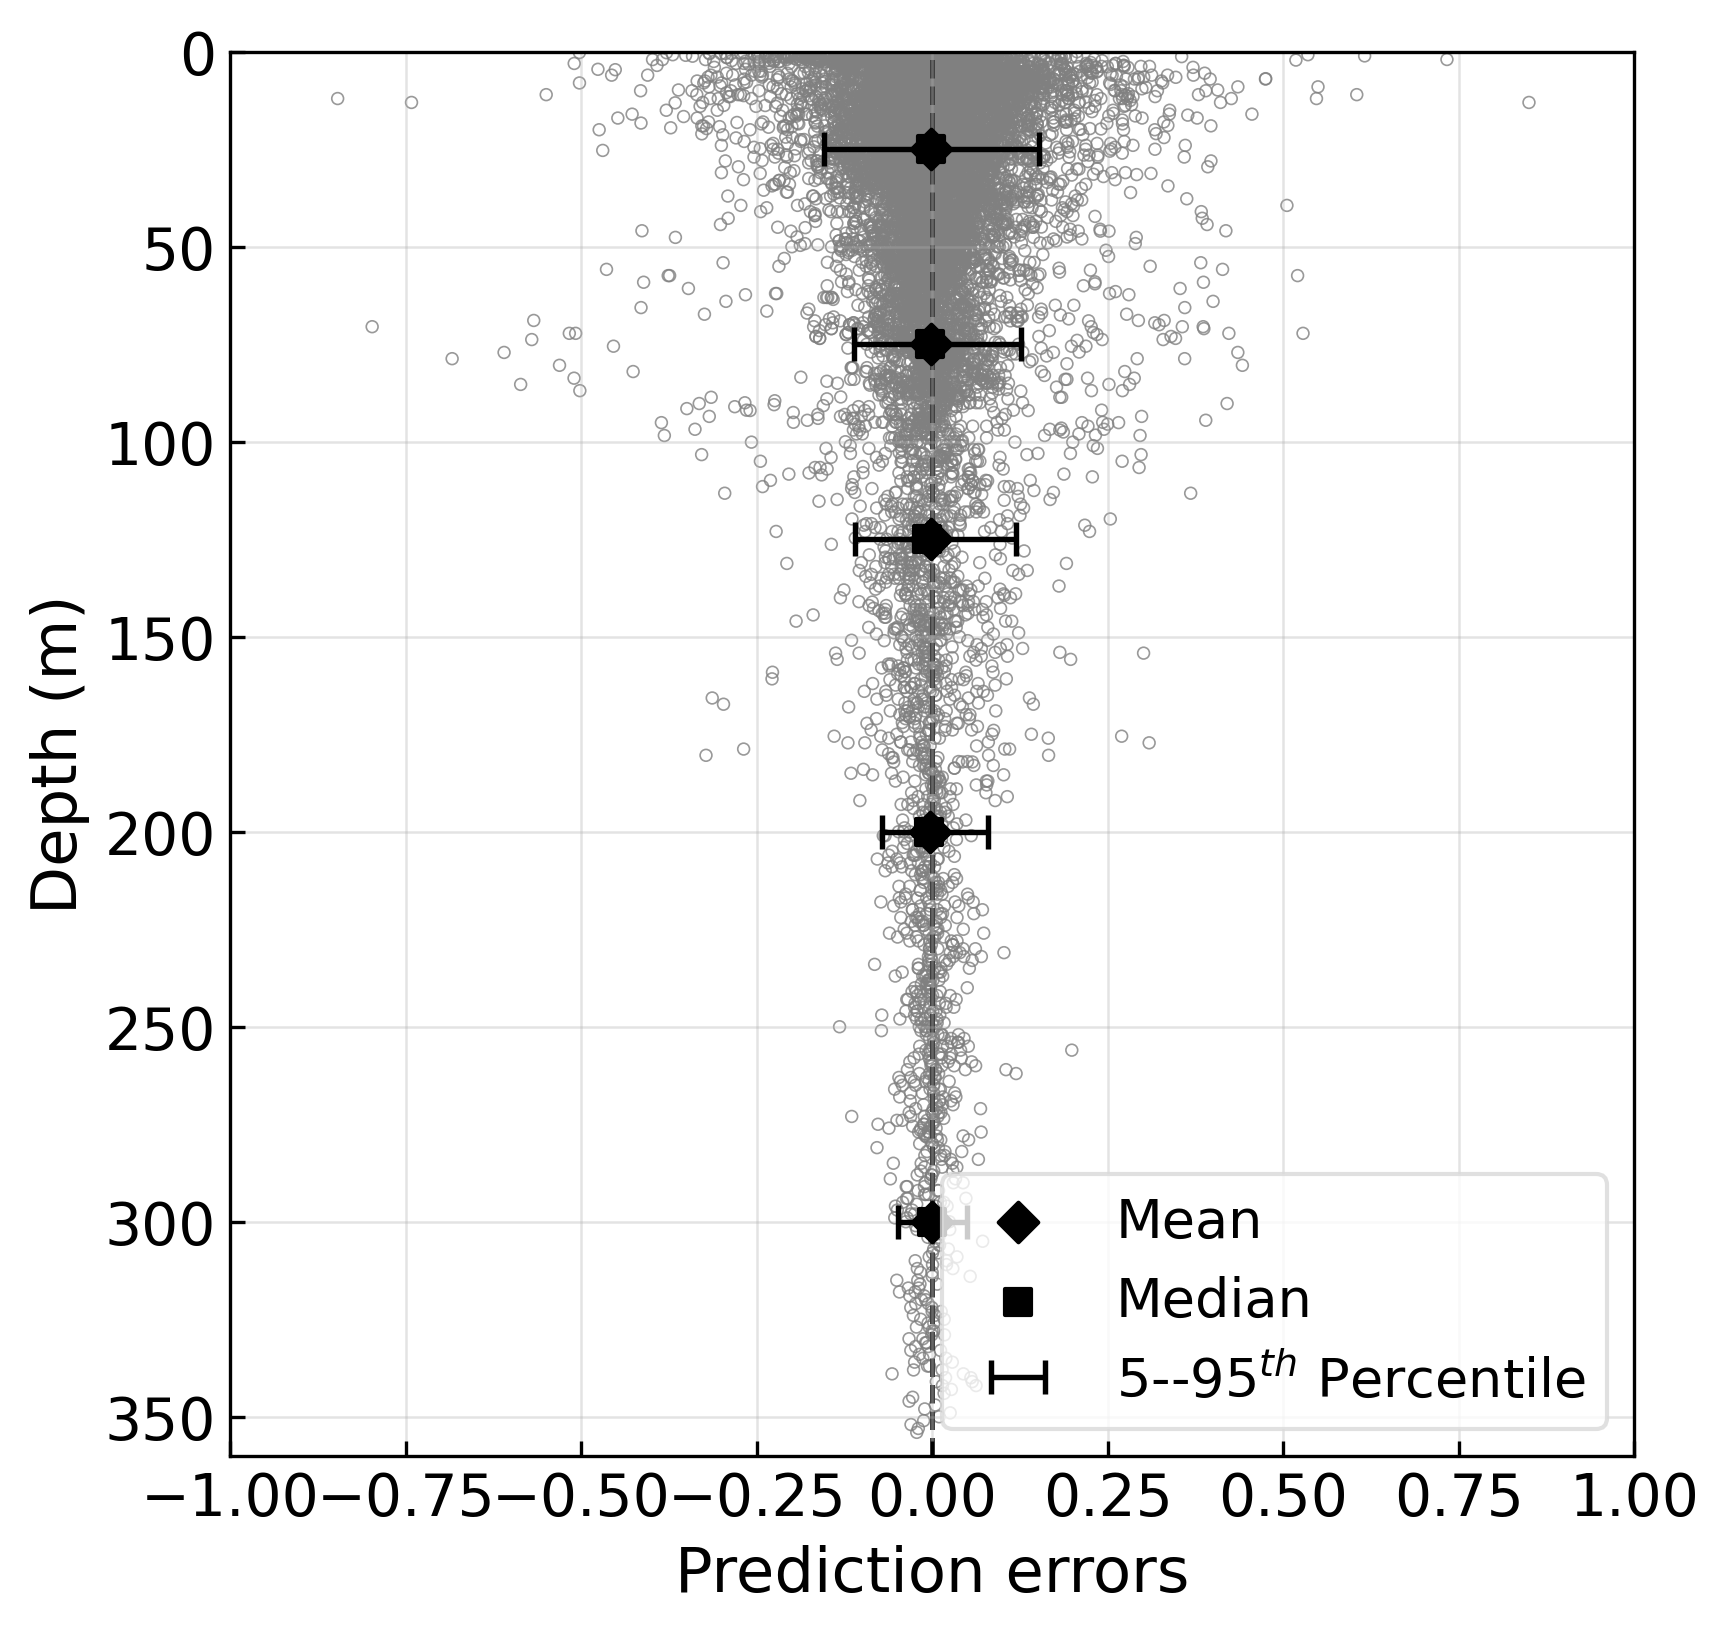

In [25]:
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams["mathtext.rm"] = "Arial"
plt.rcParams["mathtext.it"] = "Arial:italic"
plt.rcParams["mathtext.bf"] = "Arial:bold"
plt.rcParams["font.size"] = 14

x = df_residual["residual"].to_numpy()
z = df_residual["vs_depth"].to_numpy()

mask = np.isfinite(x) & np.isfinite(z)
x = x[mask]
z = z[mask]

depth_bins = np.array([0, 50, 100, 150, 250, 350, 500])
depth_centers = 0.5 * (depth_bins[:-1] + depth_bins[1:])

stats = []

for zmin, zmax, zc in zip(depth_bins[:-1], depth_bins[1:], depth_centers):
    idx = (z >= zmin) & (z < zmax)
    x_bin = x[idx]

    if len(x_bin) > 0:
        stats.append([
            zc,
            np.mean(x_bin),
            np.median(x_bin),
            np.percentile(x_bin, 5),
            np.percentile(x_bin, 95),
            len(x_bin)
        ])

stats = pd.DataFrame(
    stats,
    columns=["depth", "mean", "median", "p5", "p95", "n"]
)

fig, ax = plt.subplots(figsize=(6, 6), dpi=300)

ax.scatter(
    x, z,
    s=8,
    facecolors="none",
    edgecolors="gray",
    linewidths=0.4,
    alpha=0.8,
    label="_nolegend_",
)

ax.axvline(
    0,
    color="0.25",
    linestyle="--",
    linewidth=1.2,
    zorder=1
)

ax.scatter(
    stats["mean"],
    stats["depth"],
    marker="D",
    s=45,
    color="black",
    label="Mean",
    zorder=5
)

ax.scatter(
    stats["median"],
    stats["depth"],
    marker="s",
    s=40,
    color="black",
    label="Median",
    zorder=5
)

xerr_lower = stats["median"] - stats["p5"]
xerr_upper = stats["p95"] - stats["median"]

ax.errorbar(
    stats["median"],
    stats["depth"],
    xerr=[xerr_lower, xerr_upper],
    fmt="none",
    ecolor="black",
    elinewidth=1.3,
    capsize=4,
    capthick=1.3,
    label=r"5--95$^{th}$ Percentile",
    zorder=4
)

ax.set_xlabel(
    'Prediction errors',
    fontsize=15
)
ax.set_ylabel("Depth (m)", fontsize=15)
ax.yaxis.set_label_coords(-0.1, 0.5)

ax.set_xlim(-1, 1)
ax.set_ylim(360, 0)
ax.set_box_aspect(1)

ax.grid(
    True,
    linestyle="-",
    linewidth=0.6,
    alpha=0.35
)

ax.legend(
    loc="lower right",
    fontsize=13,
    frameon=True,
    edgecolor="0.85"
)

fig.subplots_adjust(
    left=0.18,
    right=0.96,
    bottom=0.16,
    top=0.96
)

fig.savefig(
    dir_fig + "residual_depth.png",
    format="png",
    dpi=300
)

plt.show()

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

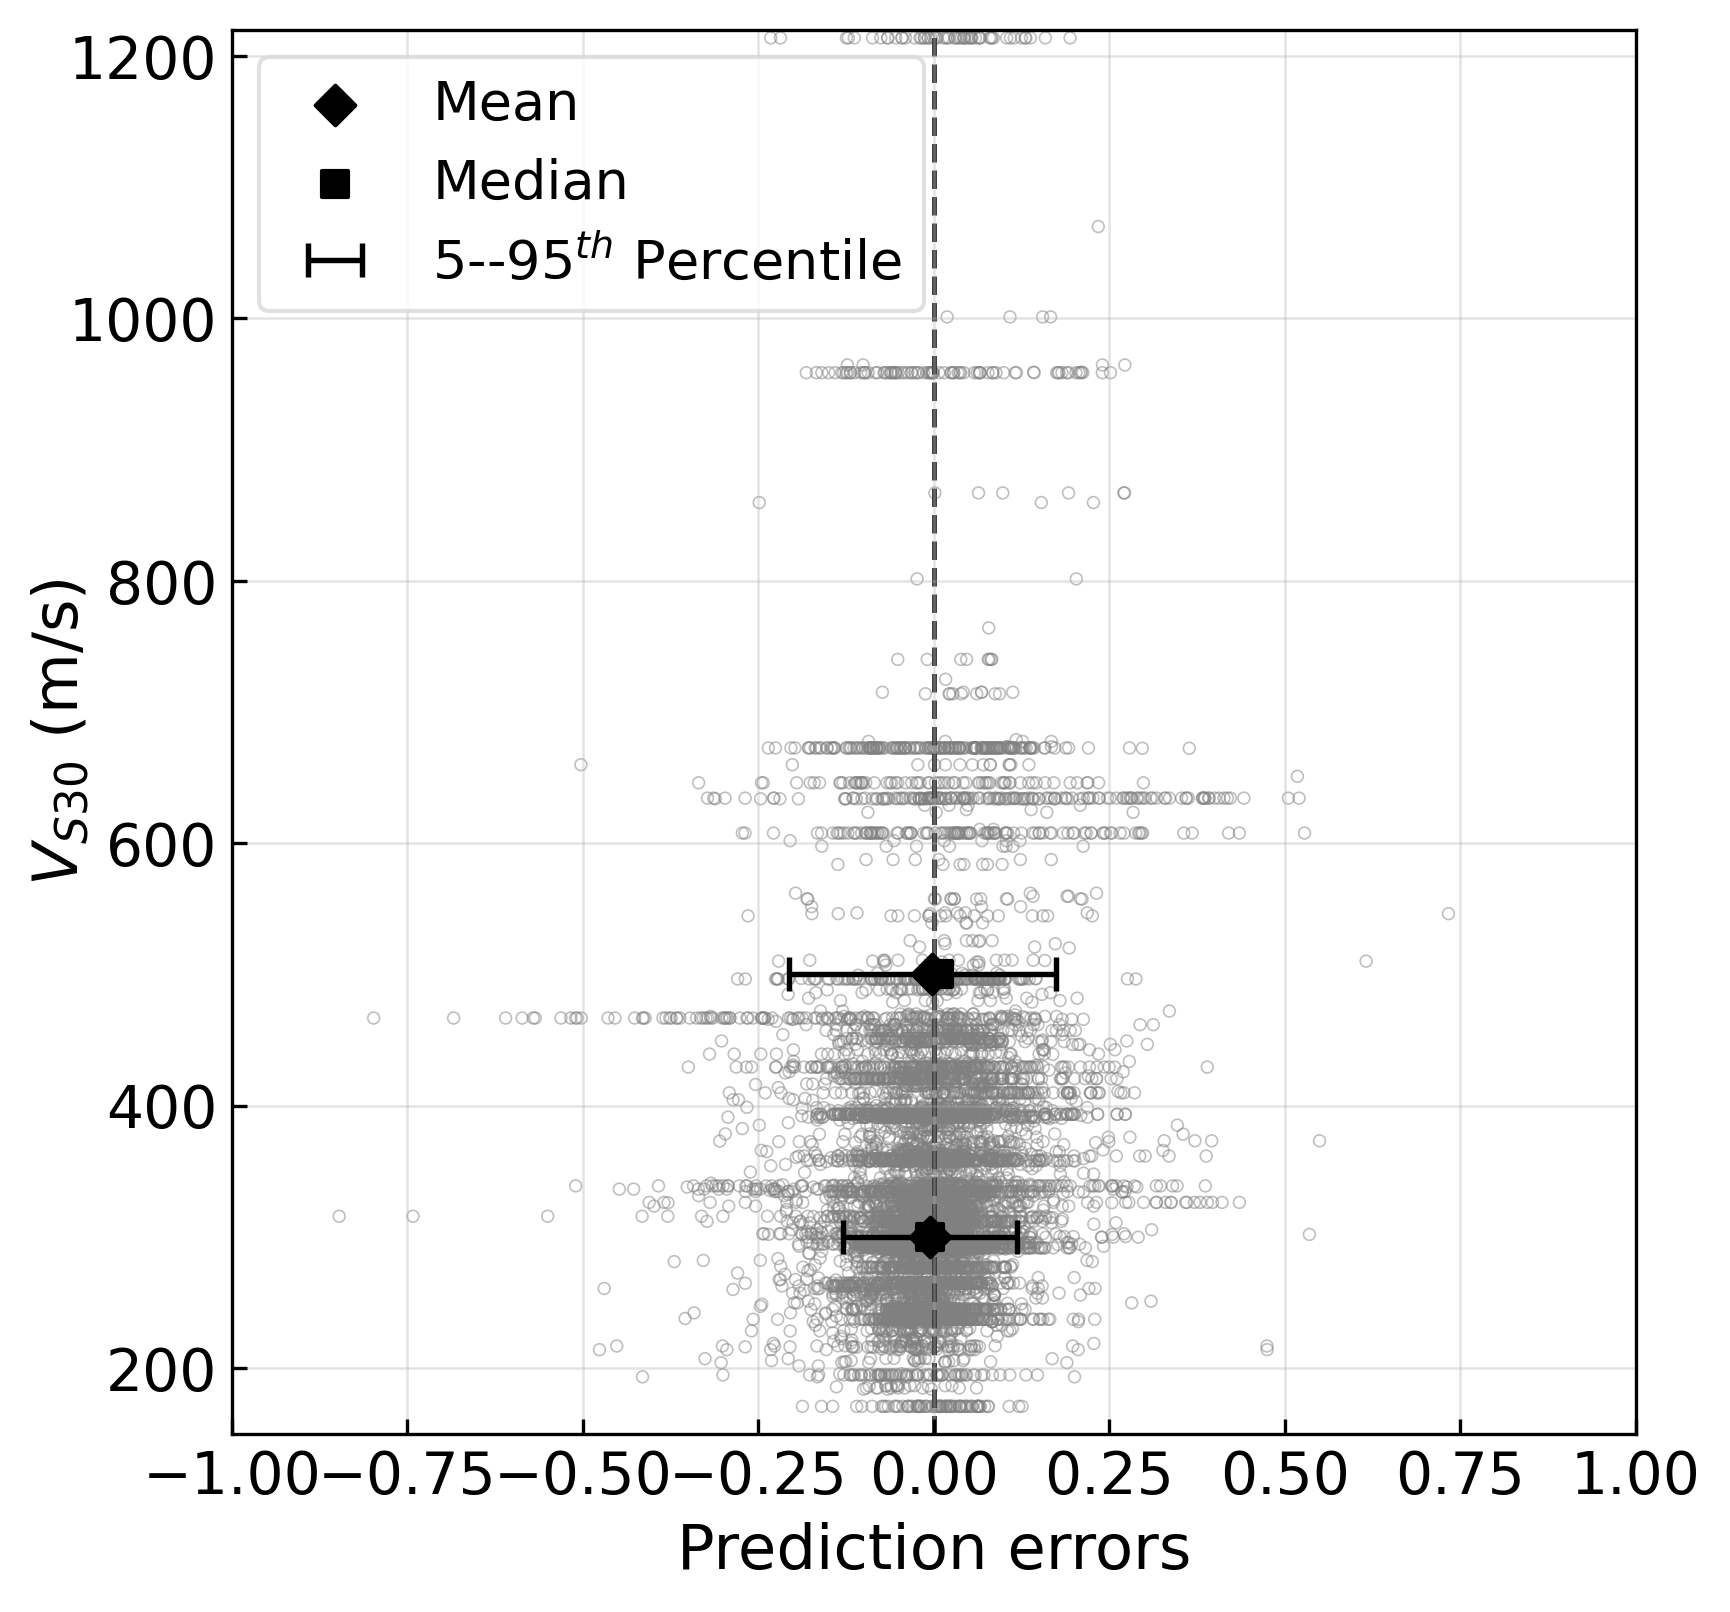

In [26]:
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams["mathtext.rm"] = "Arial"
plt.rcParams["mathtext.it"] = "Arial:italic"
plt.rcParams["mathtext.bf"] = "Arial:bold"
plt.rcParams["font.size"] = 14

x = df_residual["residual"].to_numpy()
z = df_residual["vs30"].to_numpy()

mask = np.isfinite(x) & np.isfinite(z)
x = x[mask]
z = z[mask]


vs30_bins = np.array([200, 400, 600])
vs30_centers = 0.5 * (vs30_bins[:-1] + vs30_bins[1:])

stats = []

for zmin, zmax, zc in zip(vs30_bins[:-1], vs30_bins[1:], vs30_centers):
    idx = (z >= zmin) & (z < zmax)
    x_bin = x[idx]

    if len(x_bin) > 0:
        stats.append([
            zc,
            np.mean(x_bin),
            np.median(x_bin),
            np.percentile(x_bin, 5),
            np.percentile(x_bin, 95),
            len(x_bin)
        ])

stats = pd.DataFrame(
    stats,
    columns=["vs30", "mean", "median", "p5", "p95", "n"]
)


fig, ax = plt.subplots(figsize=(6, 6), dpi=300)

ax.scatter(
    x, z,
    s=8,
    facecolors="none",
    edgecolors="gray",
    linewidths=0.4,
    alpha=0.5,
    label="_nolegend_"
)

ax.axvline(
    0,
    color="0.25",
    linestyle="--",
    linewidth=1.2,
    zorder=1
)

# Mean
ax.scatter(
    stats["mean"],
    stats["vs30"],
    marker="D",
    s=45,
    color="black",
    label="Mean",
    zorder=5
)

# Median
ax.scatter(
    stats["median"],
    stats["vs30"],
    marker="s",
    s=40,
    color="black",
    label="Median",
    zorder=5
)

# 5–95 percentile range
xerr_lower = stats["median"] - stats["p5"]
xerr_upper = stats["p95"] - stats["median"]

ax.errorbar(
    stats["median"],
    stats["vs30"],
    xerr=[xerr_lower, xerr_upper],
    fmt="none",
    ecolor="black",
    elinewidth=1.3,
    capsize=4,
    capthick=1.3,
    label=r"5--95$^{th}$ Percentile",
    zorder=4
)


ax.set_xlabel(
    'Prediction errors',
    fontsize=15
)

ax.set_ylabel(r"$V_{S30}$ (m/s)", fontsize=15)
ax.yaxis.set_label_coords(-0.1, 0.5)

ax.set_xlim(-1, 1)
ax.set_ylim(150, 1220)


ax.set_box_aspect(1)

ax.grid(
    True,
    linestyle="-",
    linewidth=0.6,
    alpha=0.35
)

ax.legend(
    loc="upper left",
    fontsize=13,
    frameon=True,
    edgecolor="0.85"
)

fig.subplots_adjust(
    left=0.18,
    right=0.96,
    bottom=0.16,
    top=0.96
)

fig.savefig(
    dir_fig + "residual_vs30.png",
    format="png",
    dpi=300
)

plt.show()

In [27]:
df_test1_val = pd.read_csv(dir_out+'Validation/test1.txt', encoding='utf-8')
df_test2_val = pd.read_csv(dir_out+'Validation/test2.txt', encoding='utf-8')

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

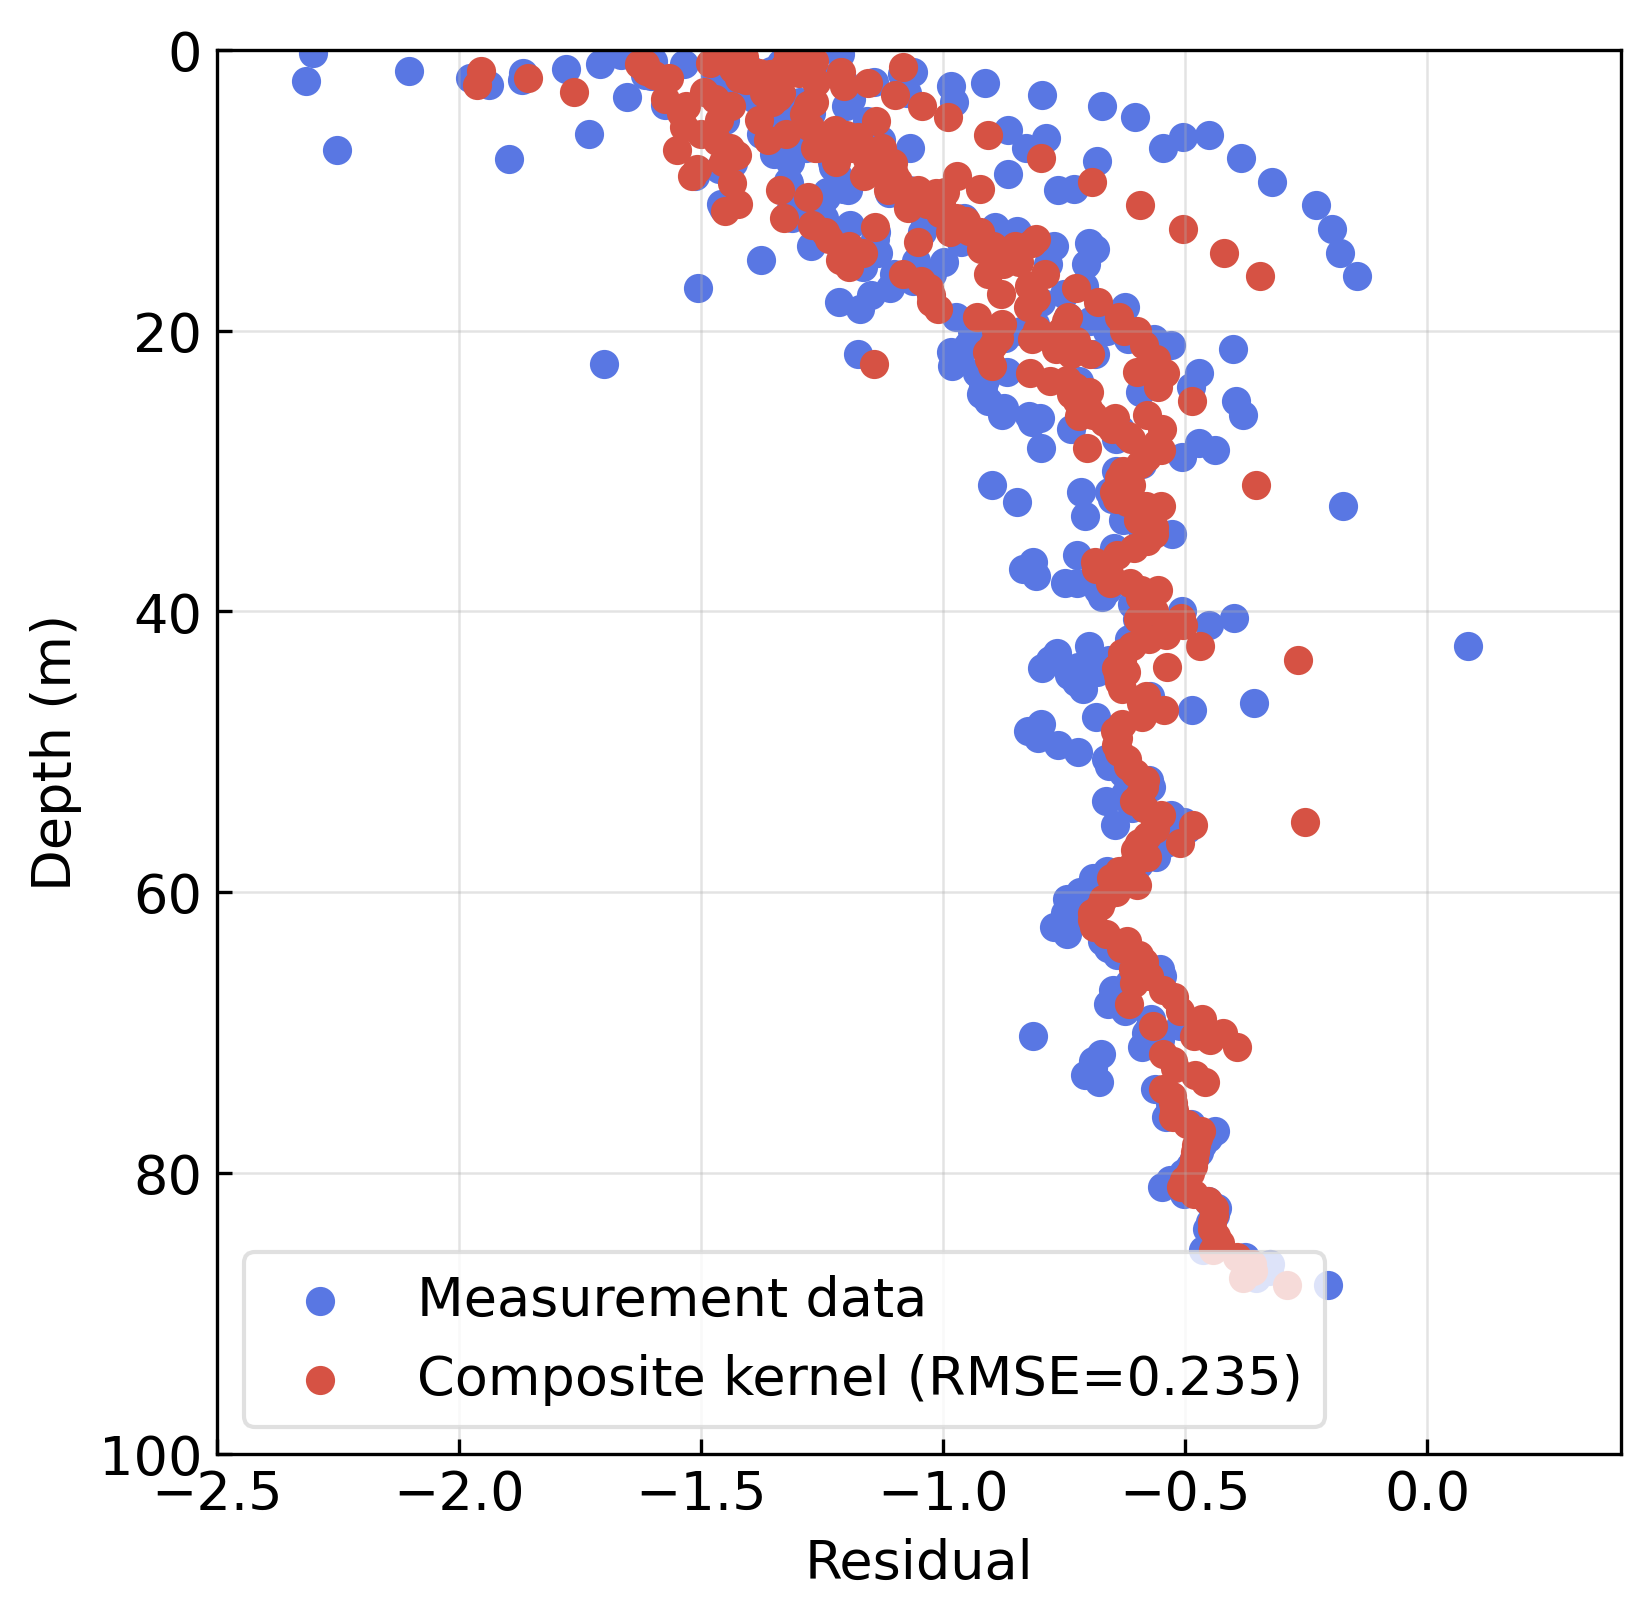

In [28]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6), dpi=300)

ax.scatter(df_test1_val['diff'], df_test1_val['vs_depth'], color=blue_color, label="Measurement data")

ax.scatter(df_test1_val['combine'], df_test1_val['vs_depth'],color=red_color, label="Composite kernel (RMSE=0.235)")

ax.set_xlim(-2.5, 0.4)
ax.set_ylim(100, 0)

ax.set_xlabel("Residual", fontsize=13)
ax.set_ylabel("Depth (m)", fontsize=13)

ax.tick_params(labelsize =13)

ax.set_box_aspect(1)

ax.grid(
    True,
    linestyle="-",
    linewidth=0.6,
    alpha=0.35
)

ax.legend(
    loc="lower left",
    fontsize=13,
    frameon=True,
    edgecolor="0.85"
)


fig.subplots_adjust(
    left=0.18,
    right=0.96,
    bottom=0.16,
    top=0.96
)


fig.savefig(
    dir_fig + "ex_com.png",
    format="png",
    dpi=300
)

plt.show()

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

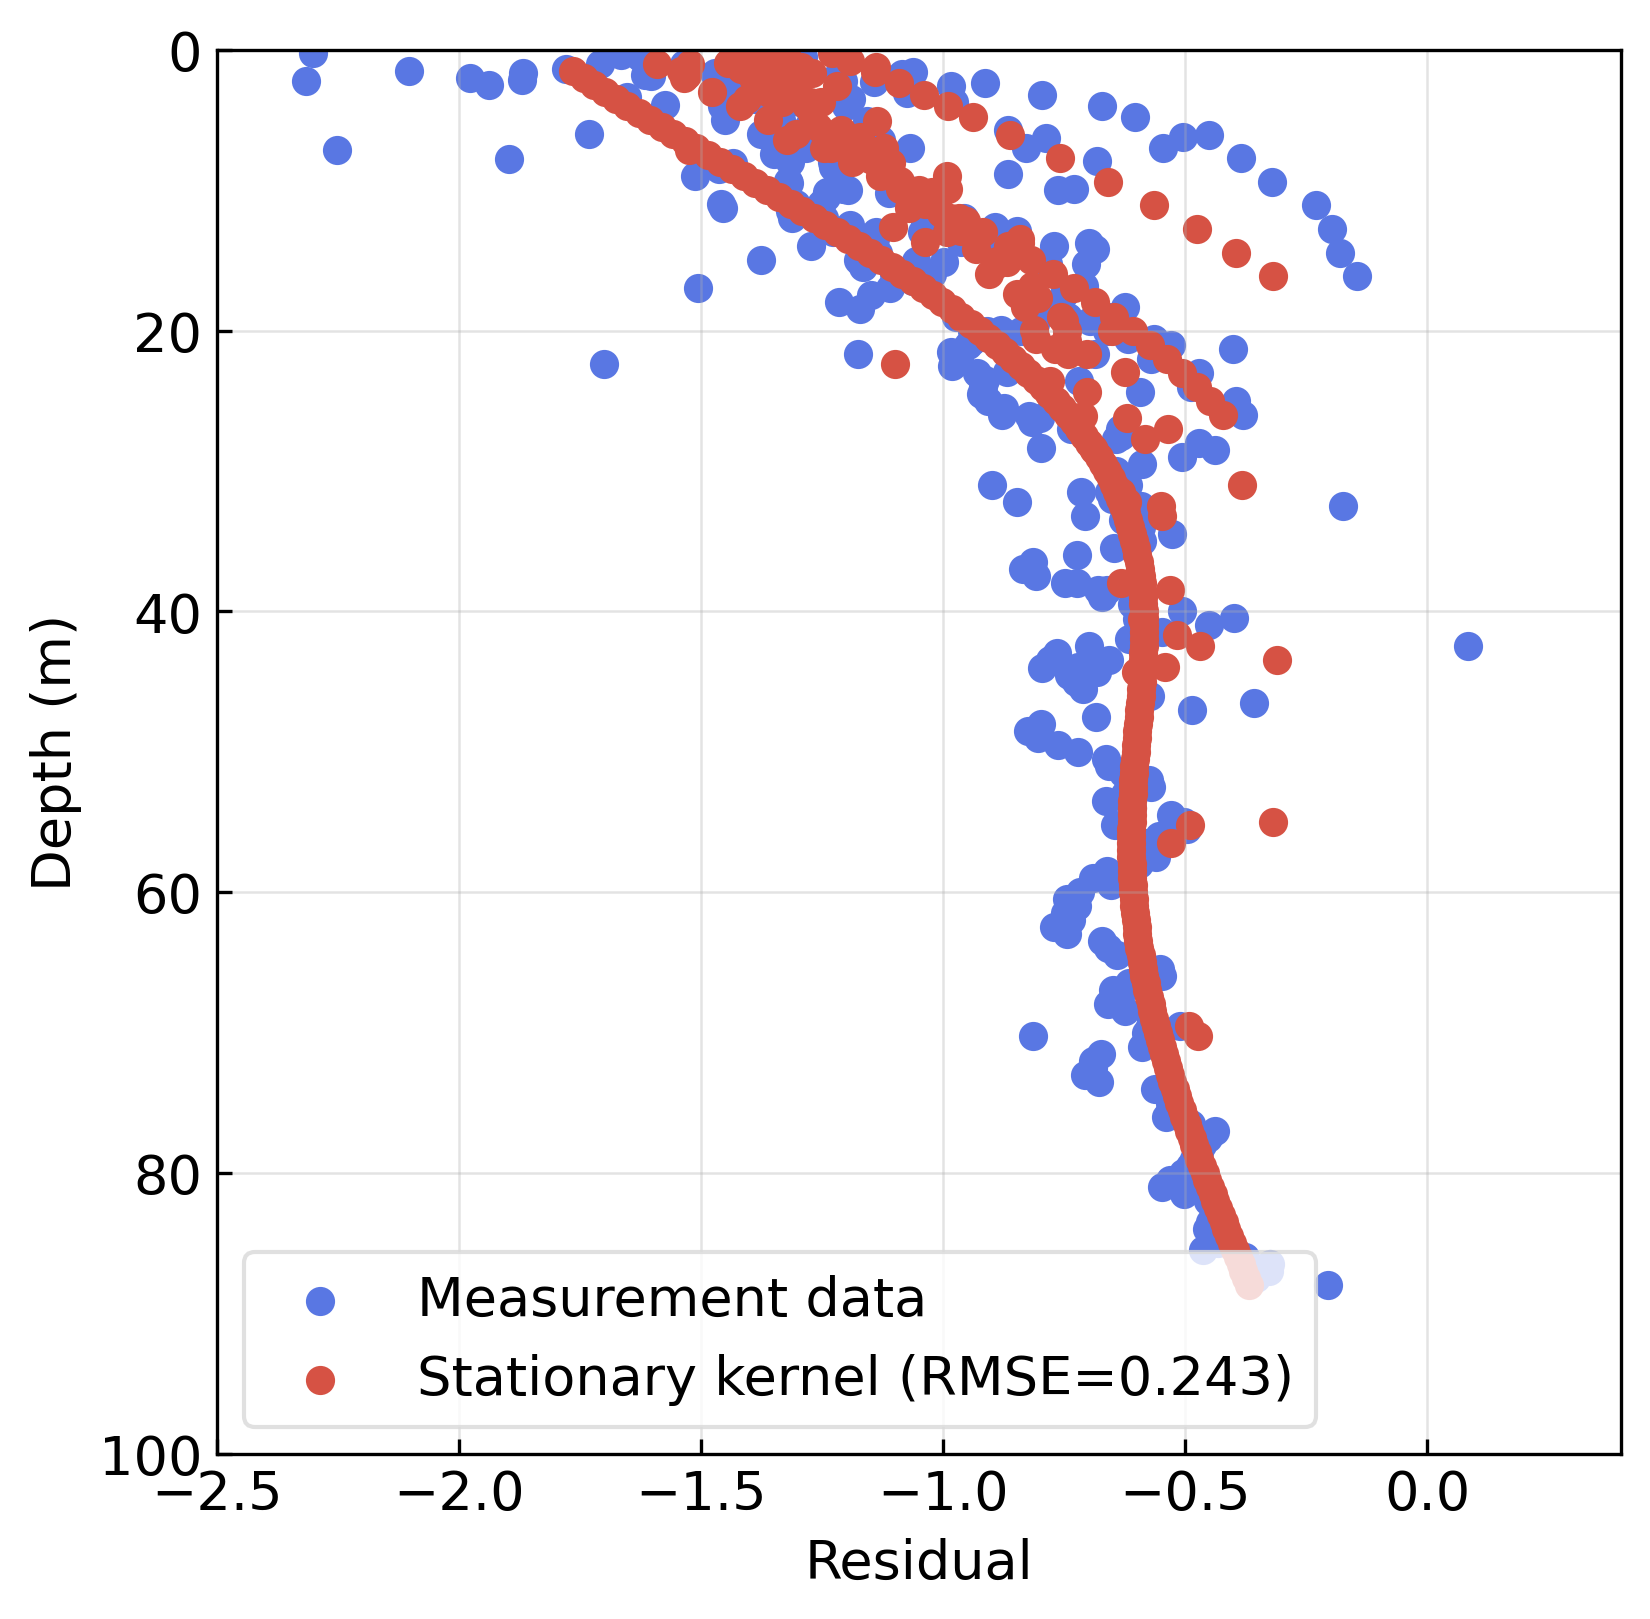

In [29]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6), dpi=300)

ax.scatter(df_test1_val['diff'], df_test1_val['vs_depth'], color=blue_color, label="Measurement data")

ax.scatter(df_test1_val['sta'], df_test1_val['vs_depth'],color=red_color, label="Stationary kernel (RMSE=0.243)")

ax.set_xlim(-2.5, 0.4)
ax.set_ylim(100, 0)

ax.set_xlabel("Residual", fontsize=13)
ax.set_ylabel("Depth (m)", fontsize=13)

ax.tick_params(labelsize =13)

ax.set_box_aspect(1)

ax.grid(
    True,
    linestyle="-",
    linewidth=0.6,
    alpha=0.35
)

ax.legend(
    loc="lower left",
    fontsize=13,
    frameon=True,
    edgecolor="0.85"
)


fig.subplots_adjust(
    left=0.18,
    right=0.96,
    bottom=0.16,
    top=0.96
)


fig.savefig(
    dir_fig + "ex_sta.png",
    format="png",
    dpi=300
)

plt.show()

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

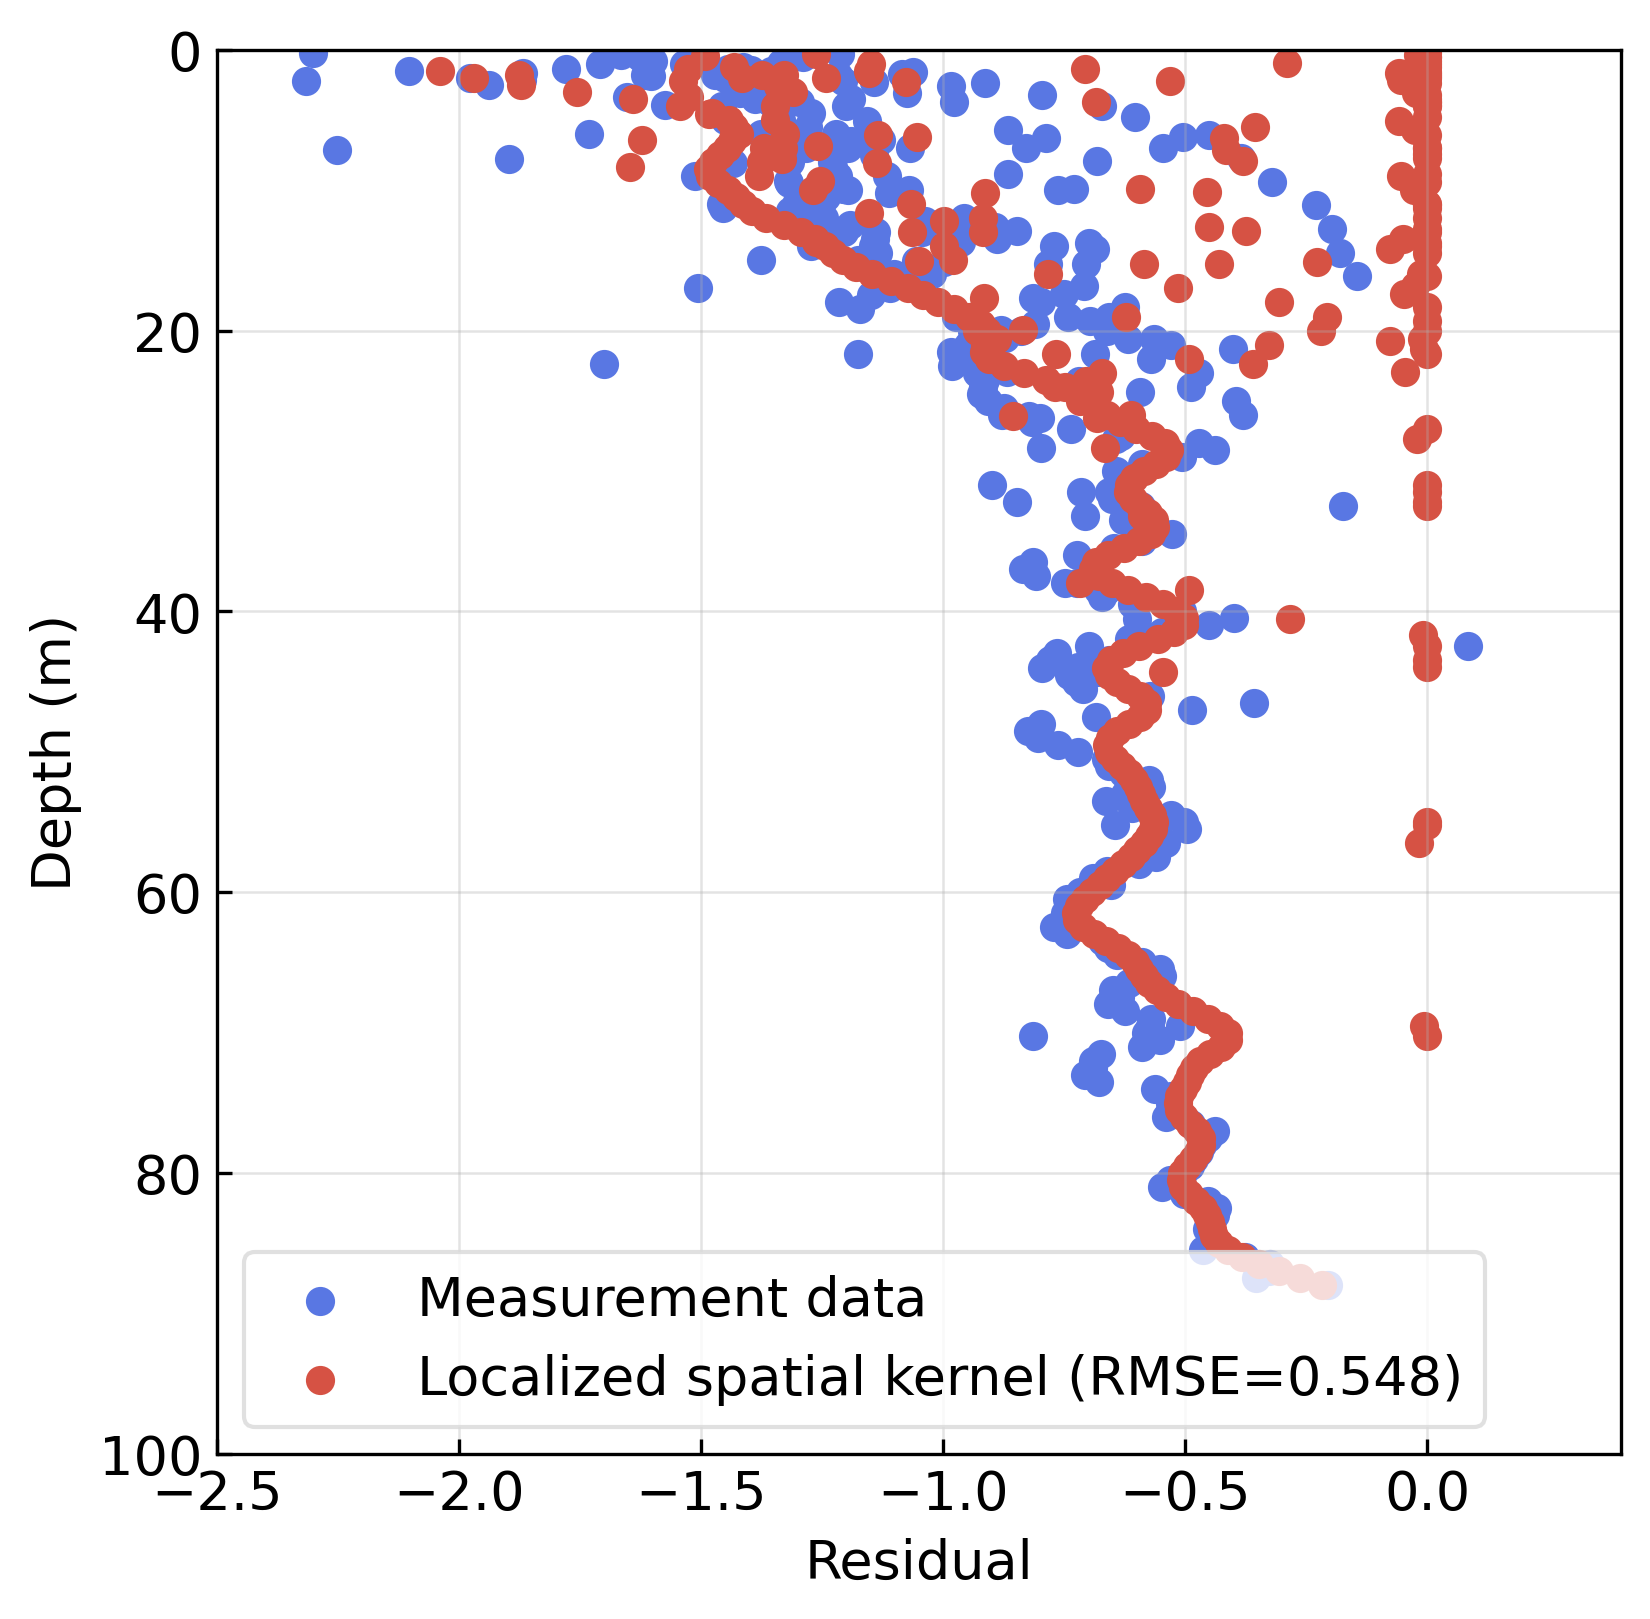

In [30]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6), dpi=300)

ax.scatter(df_test1_val['diff'], df_test1_val['vs_depth'], color=blue_color, label="Measurement data")

ax.scatter(df_test1_val['spa'], df_test1_val['vs_depth'],color=red_color, label="Localized spatial kernel (RMSE=0.548)")

ax.set_xlim(-2.5, 0.4)
ax.set_ylim(100, 0)

ax.set_xlabel("Residual", fontsize=13)
ax.set_ylabel("Depth (m)", fontsize=13)

ax.tick_params(labelsize =13)

ax.set_box_aspect(1)

ax.grid(
    True,
    linestyle="-",
    linewidth=0.6,
    alpha=0.35
)

ax.legend(
    loc="lower left",
    fontsize=13,
    frameon=True,
    edgecolor="0.85"
)


fig.subplots_adjust(
    left=0.18,
    right=0.96,
    bottom=0.16,
    top=0.96
)


fig.savefig(
    dir_fig + "ex_spa.png",
    format="png",
    dpi=300
)

plt.show()